# Baseline model: large-case annual experiment
City-specific market sizes and random choice probabilities near the demand-capacity boundary.

The notebook contains baseline optimization, edge cases, common and city-specific parameter sensitivity, mean-demand comparisons, and scenario sampling experiments.

Cost and productivity inputs follow *Baseline Model: Parameter Evidence and Setting Rationale*. These are literature-informed synthetic inputs rather than calibrated data for three actual cities. Entry costs are paid once; operating costs, demand, and capacity cover one year after entry.


## Results overview
Market sizes are 577,908,105, 770,544,140, and 963,180,175 trips/year for A, B, and C. Choice probabilities are drawn independently from {0.002, 0.005, 0.01, 0.02} for ten equiprobable scenarios using seed 2026.

- **Demand and capacity:** Maximum capacity is 8,760 x 500 = 4,380,000 trips per city. Choice probabilities at this capacity are approximately 0.0076, 0.0057, and 0.0045. Demand exceeds maximum capacity in 50%, 50%, and 80% of scenarios respectively.
- **Allocation:** All three cities are entered. The representative optimum is **(132,368,500)**. There are **72 tied allocations** with A=132, B=368 to 439, C=429 to 500, and B+C=868.
- **Service:** Mean served demand is 7,932,603 trips/year; service rate **34.93%**; utilization 90.6%; mean unused capacity 827,397 trips.
- **Costs:** Objective **USD 166,263,859**; no-entry baseline USD 227,117,885; improvement **USD 60,854,026**.
- **Marginal values:** At c+=0 the expected net value of an additional fully utilized capacity increment is governed by 87,600 x P(demand > allocated capacity) - 7,972. In A the first 131 vehicles yield USD 79,628 each, the 132nd yields approximately USD 78,117, and subsequent vehicles yield USD 53,348 in the next interval. The relevant B and C intervals yield USD 62,108. This allocates 132 vehicles to A and 868 to B and C, with equal marginal values producing ties.
- **Entry into A:** The baseline is only USD 392,967 better than (0,500,500). A leaves the optimal allocation when common F crosses a threshold between the sampled values USD 3.72 million and USD 3.94 million.
- **Sensitivity:** Sampled M multipliers >=1.0625 or p multipliers >=1.25 yield (0,500,500). A city limit >=750 yields (0,440,560). Q=900 gives (0,400,500); Q=1,500 gives (500,500,500). Sampled kappa <=8,212.5 gives (0,500,500). Common c-=5 gives (0,500,500), c-=2 gives (0,0,500), and alpha<=0.7 gives (0,500,500).
- **Mean-demand decisions:** Evaluation under the ten scenarios gives extra costs of roughly USD 0.39 million to USD 8.14 million across tied mean-demand solutions.
- **Sampling stability:** At 50 scenarios, allocations vary across seeds and extra cost under the common distribution reaches USD 1.73 million. At 500 scenarios all five seeds give zero extra cost.
- **Validation:** Eight small enumeration tests, eight edge cases, MILP-DP comparisons, and 50/100/500 scenarios with five seeds each.

The results concern the specified synthetic instance, not estimated optimal fleets for actual cities.


In [1]:
import importlib.util, sys, subprocess
packages = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy>=1.9',
            'matplotlib':'matplotlib', 'IPython':'ipython'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
from copy import deepcopy
from itertools import product
import hashlib, json, html
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML
fonts={f.name for f in font_manager.fontManager.ttflist}
kfont=next((f for f in ['Malgun Gothic','NanumGothic','Noto Sans CJK KR','AppleGothic'] if f in fonts),None)
plt.rcParams.update({'font.family':kfont or 'DejaVu Sans','axes.unicode_minus':False,
                     'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
def L(ko,en): return en
def note(s): display(Markdown(s))
def show(title,df):
    note('**'+title+'**');display(df)
def detail(title,df):
    display(HTML('<details><summary>'+html.escape(title)+'</summary>'+df.to_html(index=False,float_format=lambda x:f'{x:,.4f}')+'</details>'))
FIGURES=[]
def showfig(fig,name):
    fig.tight_layout();FIGURES.append((name,fig));display(fig);plt.close(fig)
COLORS=['#2563a6','#c98a21','#39796b']

## 1. Baseline experiment
### 1-1. Inputs and interpretation
Market size $M_c$ differs across cities, at 0.75, 1, and 1.25 times the reference value. Choice probabilities $p_c^s$ are drawn from {0.002, 0.005, 0.01, 0.02}. Costs, productivity, and city vehicle limits are identical, so city heterogeneity comes from demand.


In [2]:
cities=['A','B','C']
M=np.array([577_908_105.,770_544_140.,963_180_175.])
kappa=np.full(3,8_760.)
qbar=np.full(3,500,dtype=int)
F=np.full(3,3_500_000.)
K=np.full(3,7_972.)
c_plus=np.zeros(3)
c_minus=np.full(3,10.)
Q=1_000
P_LEVELS=np.array([.002,.005,.01,.02]);S=10;P_SEED=2026
p=np.random.default_rng(P_SEED).choice(P_LEVELS,size=(S,3))                      
S,C=p.shape
probability=np.full(S,1/S)
D=p*M
BASE={k:np.asarray(globals()[k]).copy() for k in ['M','kappa','qbar','F','K','c_plus','c_minus','p']}
BASE['Q']=Q
input_specs=[
 ('M','trips/year','0.75, 1, and 1.25 times the reference value 770,544,140 (= 38,527,207 / 0.05); experimental proxy'),
 ('kappa','trips/vehicle/year','24 x 365; based on reported operating activity, not an observed physical capacity limit'),
 ('qbar','vehicles','500 vehicles per city; assumed'),
 ('F','USD/city entry','(300,000 + 2,500,000) x 1.25; the additional 25% is assumed'),
 ('K','USD/vehicle/year','4,334 + 1,131 + 1,694 + 813; personal vehicle ownership cost reference'),
 ('c_plus','USD/unused capacity trip','No additional idle penalty; assumed'),
 ('c_minus','USD/unmet trip','Assumed revenue 18 minus variable cost 8; not an empirical contribution margin estimate')]
show('City inputs',pd.DataFrame([{'Input':key,'Unit':unit,**dict(zip(cities,BASE[key])),'Basis and limitations':why} for key,unit,why in input_specs]))
show('Common settings',pd.DataFrame([
 ('Fleet limit Q',Q),('Scenario count',S),('Scenario probability',f'Each 1/{S}'),
 ('Evaluation period','One year after entry; F paid once, K annual'),
 ('Choice probability p','Independent uniform draws from {0.002, 0.005, 0.01, 0.02} by city and scenario; seed 2026'),
 ('Demand generation','D = M × p'),
 ('Operating assumptions','Common y and q across scenarios; no intercity transfers or capacity sharing')],columns=['Item','Setting']))
scen=pd.DataFrame(np.column_stack([p,D]),columns=['p_A','p_B','p_C','D_A','D_B','D_C']);scen.insert(0,'Scenario',np.arange(1,S+1))
show(f'Joint scenarios: p is choice probability; 1/{S} is the scenario occurrence probability',scen)
show('Draw counts by candidate value and city',pd.DataFrame({f'p={lvl:g}':[int((p[:,c]==lvl).sum()) for c in range(3)] for lvl in P_LEVELS},index=cities))
assert np.allclose(M,770_544_140*np.array([.75,1.,1.25]))
assert 24*365 == kappa[0] and (300_000+2_500_000)*1.25 == F[0]
assert 4334+1131+1694+813 == K[0]
assert p.shape==(10,3) and set(np.unique(p).tolist())<=set(P_LEVELS.tolist())

k=np.arange(1,501)
for c in range(3):
    inc=(np.minimum(D[:,[c]],kappa[c]*k)-np.minimum(D[:,[c]],kappa[c]*(k-1))).mean(axis=0)
    val=pd.Series(c_minus[c]*inc-K[c],index=k)
    print(cities[c]); print(val[val.diff().abs().fillna(1)>0.5].round(0))                  


A
1      79628.0
132    78117.0
133    53348.0
330    50829.0
331    35828.0
dtype: float64
B
1      79628.0
176    78285.0
177    62108.0
440    57070.0
441    35828.0
dtype: float64
C
1      79628.0
220    77949.0
221    62108.0
dtype: float64


**City inputs**

,Input,Unit,A,B,C,Basis and limitations
0,M,trips/year,577908105.0,770544140.0,963180175.0,"0.75, 1, and 1.25 times the reference value 77..."
1,kappa,trips/vehicle/year,8760.0,8760.0,8760.0,24 x 365; based on reported operating activity...
2,qbar,vehicles,500.0,500.0,500.0,500 vehicles per city; assumed
3,F,USD/city entry,3500000.0,3500000.0,3500000.0,"(300,000 + 2,500,000) x 1.25; the additional 2..."
4,K,USD/vehicle/year,7972.0,7972.0,7972.0,"4,334 + 1,131 + 1,694 + 813; personal vehicle ..."
5,c_plus,USD/unused capacity trip,0.0,0.0,0.0,No additional idle penalty; assumed
6,c_minus,USD/unmet trip,10.0,10.0,10.0,Assumed revenue 18 minus variable cost 8; not ...


**Common settings**

,Item,Setting
0,Fleet limit Q,1000
1,Scenario count,10
2,Scenario probability,Each 1/10
3,Evaluation period,"One year after entry; F paid once, K annual"
4,Choice probability p,"Independent uniform draws from {0.002, 0.005, ..."
5,Demand generation,D = M × p
6,Operating assumptions,Common y and q across scenarios; no intercity ...


**Joint scenarios: p is choice probability; 1/10 is the scenario occurrence probability**

,Scenario,p_A,p_B,p_C,D_A,D_B,D_C
0,1,0.020,0.002,0.002,1.155816e+07,1541088.28,1.926360e+06
1,2,0.010,0.005,0.005,5.779081e+06,3852720.70,4.815901e+06
2,3,0.002,0.005,0.010,1.155816e+06,3852720.70,9.631802e+06
3,4,0.005,0.020,0.020,2.889541e+06,15410882.80,1.926360e+07
4,5,0.010,0.020,0.010,5.779081e+06,15410882.80,9.631802e+06
5,6,0.002,0.020,0.010,1.155816e+06,15410882.80,9.631802e+06
6,7,0.002,0.005,0.002,1.155816e+06,3852720.70,1.926360e+06
7,8,0.020,0.010,0.020,1.155816e+07,7705441.40,1.926360e+07
8,9,0.005,0.010,0.010,2.889541e+06,7705441.40,9.631802e+06
9,10,0.020,0.002,0.010,1.155816e+07,1541088.28,9.631802e+06


**Draw counts by candidate value and city**

,p=0.002,p=0.005,p=0.01,p=0.02
A,3,2,2,3
B,2,3,2,3
C,2,1,5,2


### 1-2. Demand and capacity
Compare demand and maximum capacity before interpreting allocation sensitivity.
$$D_c^s=M_cp_c^s,\quad T_c^s=\min(D_c^s,\kappa_cq_c).$$
$$\text{Service rate}(\%)=\frac{\frac1{|S|}\sum_s\sum_cT_c^s}{\frac1{|S|}\sum_s\sum_cD_c^s}\times100.$$
$$Z_0=\frac1{|S|}\sum_s\sum_cc_c^-D_c^s,\quad
Z=\sum_cF_cy_c+\sum_cK_cq_c+\frac1{|S|}\sum_s\sum_c(c_c^+O_c^s+c_c^-U_c^s),\quad
\text{Improvement}=Z_0-Z.$$
The service rate is undefined at zero demand. Costs are in USD; demand and service are annual trip counts.


**Demand and maximum supply**

,City,Minimum scenario demand,Maximum scenario demand,Mean demand,Maximum city capacity,Mean demand / vehicle capacity,Minimum demand / maximum city capacity,Choice probability at capacity (kappa*qbar/M)
0,A,1155816.21,11558162.1,5.547918e+06,4380000.0,633.323951,0.263885,0.007579
1,B,1541088.28,15410882.8,7.628387e+06,4380000.0,870.820432,0.351847,0.005684
2,C,1926360.35,19263603.5,9.535484e+06,4380000.0,1088.525540,0.439808,0.004547


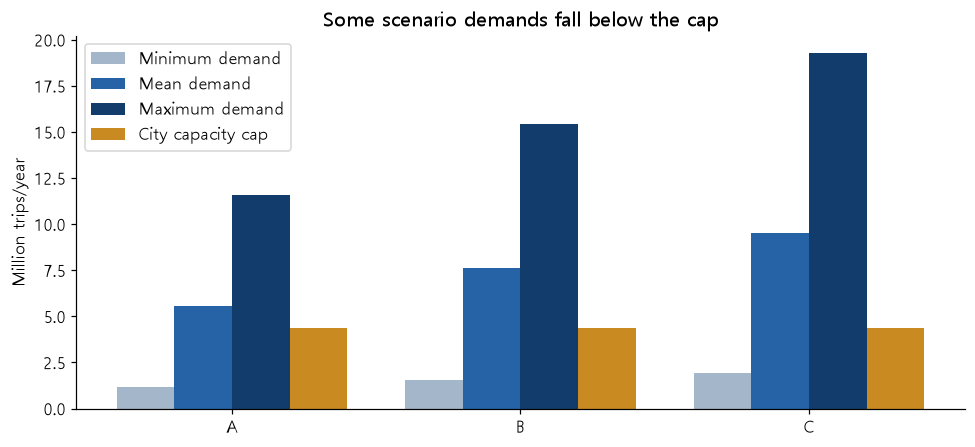

Vehicles required to match mean demand by city, before integer rounding: **2,592.7 vehicles**. Total fleet limit: 1,000 vehicles; sum of city limits: 1,500 vehicles.

Minimum demand occurs in scenario 3 in city A (p=0.002) at 1,155,816 trips, maximum city capacity 4,380,000 trips, ratio **0.26**. Choice probabilities at maximum capacity by city: A 0.0076, B 0.0057, C 0.0045; candidate range 0.002~0.02.

Demand is below capacity in some city-scenario pairs, allowing unused capacity.

In [3]:
cap=kappa*qbar
scale_table=pd.DataFrame({'City':cities,'Minimum scenario demand':D.min(axis=0),'Maximum scenario demand':D.max(axis=0),
    'Mean demand':D.mean(axis=0),'Maximum city capacity':cap,
    'Mean demand / vehicle capacity':D.mean(axis=0)/kappa,
    'Minimum demand / maximum city capacity':D.min(axis=0)/cap,
    'Choice probability at capacity (kappa*qbar/M)':cap/M})
show('Demand and maximum supply',scale_table)
SHORTAGE=bool((D.min(axis=0)>=cap).all())                               
fig,ax=plt.subplots(figsize=(9,4.2))
x=np.arange(C);w=.2
for dx,vals,label,color in [(-1.5*w,D.min(axis=0),L('Minimum demand','Minimum demand'),'#a4b7ca'),
 (-.5*w,D.mean(axis=0),L('Mean demand','Mean demand'),'#2563a6'),
 (.5*w,D.max(axis=0),L('Maximum demand','Maximum demand'),'#123c6b'),
 (1.5*w,cap,L('Maximum city capacity','City capacity cap'),'#c98a21')]:
    ax.bar(x+dx,vals/1e6,w,label=label,color=color)
ax.set_xticks(x,cities);ax.set_ylabel(L('Million trips/year','Million trips/year'));ax.legend()
ax.set_title(L('Minimum demand exceeds maximum city capacity','Even minimum demand exceeds each city capacity cap') if SHORTAGE
             else L('Demand is below capacity in some scenarios','Some scenario demands fall below the cap'))
showfig(fig,'01_scale')
smin=np.unravel_index(D.argmin(),D.shape)
note(f"Vehicles required to match mean demand by city, before integer rounding: **{(D.mean(axis=0)/kappa).sum():,.1f} vehicles**. "
     f"Total fleet limit: {Q:,} vehicles; sum of city limits: {qbar.sum():,} vehicles.")
note(f"Minimum demand occurs in scenario {smin[0]+1} in city {cities[smin[1]]} (p={p[smin]:g}) at {D.min():,.0f} trips, "
     f"maximum city capacity {cap[0]:,.0f} trips, ratio **{D.min()/cap[0]:.2f}**. "
     f"Choice probabilities at maximum capacity by city: {', '.join(f'{cc} {v:.4f}' for cc,v in zip(cities,cap/M))}; candidate range {P_LEVELS.min():g}~{P_LEVELS.max():g}.")
note('Demand exceeds maximum capacity in **every city and scenario**.' if SHORTAGE else 'Demand is below capacity in some city-scenario pairs, allowing unused capacity.')


### 1-3. Optimization and independent verification
The MILP uses y, q, O, U and the baseline constraints. Trips and money are scaled to millions internally for numerical stability, then converted back to original units.

An independent exact dynamic program (DP) evaluates integer vehicle counts by city and combines them within the total fleet limit. It computes service values directly and does not share the MILP objective matrix. Small-instance exhaustive tests validate the DP first.

The solver reports the number of optimal q vectors and each city's allocation range, displaying at most 12 tied vectors. With F=0, redundant y=1 in a city with q=0 does not count as a distinct fleet allocation. The representative solution minimizes the number of entered cities, then selects q lexicographically.


In [4]:
TOL_GAIN=1e-5                           
TOL_USD=.05                                
SOLVE_LOG=[]; CACHE={}
def validate(data):
    n=len(data['M']);assert n==3, 'This notebook requires exactly three cities.'
    for key in ['M','kappa','qbar','F','K','c_plus','c_minus']:
        a=np.asarray(data[key]);assert a.shape==(n,) and np.isfinite(a).all() and (a>=0).all(),key
    assert np.equal(data['qbar'],np.floor(data['qbar'])).all()
    assert isinstance(data['Q'],(int,np.integer)) and data['Q']>=0
    pp=np.asarray(data['p']);assert pp.ndim==2 and pp.shape[1]==n and len(pp)>0
    assert np.isfinite(pp).all() and ((pp>=0)&(pp<=1)).all()

def evaluate(data,q,y=None):
    qq=np.asarray(q,dtype=int);yy=(qq>0).astype(int) if y is None else np.asarray(y,dtype=int)
    assert ((yy==0)|(yy==1)).all() and (qq>=0).all()
    assert (qq<=data['qbar']*yy).all() and qq.sum()<=data['Q']
    demand=data['p']*data['M'];capacity=data['kappa']*qq
    served=np.minimum(demand,capacity);unused=np.maximum(capacity-demand,0);unmet=np.maximum(demand-capacity,0)
    comp=np.array([data['F']@yy,data['K']@qq,np.mean(unused@data['c_plus']),np.mean(unmet@data['c_minus'])])
    no_entry=float(np.mean(demand@data['c_minus']))
                                               
    gain=float(np.mean(served@data['c_minus'])-comp[:3].sum())
    ed=float(demand.sum(axis=1).mean());st=float(served.sum(axis=1).mean())
    return dict(q=tuple(qq),y=tuple(yy),components=comp,cost=float(comp.sum()),gain=gain,no_entry=no_entry,
        demand=ed,served=st,unmet=float(unmet.sum(axis=1).mean()),unused=float(unused.sum(axis=1).mean()),
        service_rate=st/ed if ed else np.nan,utilization=st/capacity.sum() if capacity.sum() else np.nan,
        D=demand,O=unused,U=unmet,capacity=capacity)

def dp_oracle(data):
    n=len(data['M']);B=min(int(data['Q']),int(sum(data['qbar'])))
    caps=np.minimum(data['qbar'],B).astype(int)
    gains=[]
    for c in range(n):
        qs=np.arange(caps[c]+1);dd=data['p'][:,c]*data['M'][c]
        cap=data['kappa'][c]*qs
                                                       
        service=np.minimum(dd[:,None],cap).mean(axis=0)
        idle=np.maximum(cap-dd[:,None],0).mean(axis=0)
        gains.append(data['c_minus'][c]*service-data['c_plus'][c]*idle
                     -data['K'][c]*qs-data['F'][c]*(qs>0))
    best=np.full((n+1,B+1),-np.inf);best[n,0]=0
    counts=np.zeros((n+1,B+1),dtype=np.int64);counts[n,0]=1
    entries=np.full((n+1,B+1),n+1,dtype=int);entries[n,0]=0
    lo=np.full((n+1,B+1,n),np.inf);hi=np.full((n+1,B+1,n),-np.inf)
    lo[n,0]=0;hi[n,0]=0
    for i in range(n-1,-1,-1):
        for v in range(caps[i]+1):
            length=B-v+1;src=best[i+1,:length];valid=np.isfinite(src)
            cand=src+gains[i][v];dst=best[i,v:]
            better=valid&(cand>dst+TOL_GAIN)
            tied=valid&~better&(np.abs(cand-np.where(np.isfinite(dst),dst,0))<=TOL_GAIN)
            child=counts[i+1,:length];ec=entries[i+1,:length]+int(v>0)
            counts[i,v:][better]=child[better];counts[i,v:][tied]+=child[tied]
            entries[i,v:][better]=ec[better]
            entries[i,v:][tied]=np.minimum(entries[i,v:][tied],ec[tied])
            clo=lo[i+1,:length].copy();chi=hi[i+1,:length].copy();clo[:,i]=v;chi[:,i]=v
            lo[i,v:][better]=clo[better];hi[i,v:][better]=chi[better]
            lo[i,v:][tied]=np.minimum(lo[i,v:][tied],clo[tied]);hi[i,v:][tied]=np.maximum(hi[i,v:][tied],chi[tied])
            dst[better]=cand[better]
    optimum=float(best[0].max());budgets=np.flatnonzero(np.abs(best[0]-optimum)<=TOL_GAIN)
    fewest=int(entries[0,budgets].min())
    def reconstruct(b):
        result=[]
        for i in range(n):
            for v in range(min(caps[i],b)+1):
                if (abs(gains[i][v]+best[i+1,b-v]-best[i,b])<=TOL_GAIN
                    and int(v>0)+entries[i+1,b-v]==entries[i,b]):
                    result.append(v);b-=v;break
            else:raise AssertionError('DP path reconstruction failed')
        return tuple(result)
    rep=min(reconstruct(int(b)) for b in budgets if entries[0,b]==fewest)
    samples=[]
    def walk(i,b,path):
        if len(samples)>=12:return
        if i==n:
            samples.append(tuple(path));return
        for v in range(min(caps[i],b)+1):
            if abs(gains[i][v]+best[i+1,b-v]-best[i,b])<=TOL_GAIN:
                walk(i+1,b-v,path+[v])
                if len(samples)>=12:return
    for b in budgets:
        walk(0,int(b),[])
        if len(samples)>=12:break
    return dict(gain=optimum,q=rep,count=int(counts[0,budgets].sum()),samples=samples,
                q_min=lo[0,budgets].min(axis=0).astype(int),q_max=hi[0,budgets].max(axis=0).astype(int))

def solve(data,label=''):
    validate(data)
    key=hashlib.sha256(json.dumps({k:np.asarray(v).tolist() for k,v in data.items()},sort_keys=True).encode()).hexdigest()
    if key in CACHE:return CACHE[key]
    ns,nc=data['p'].shape;demand=data['p']*data['M']
    scale=1e6 if demand.max()>=1e6 else 1.0
    iy=np.arange(nc);iq=np.arange(nc,2*nc)
    io=np.arange(2*nc,2*nc+ns*nc).reshape(ns,nc)
    iu=np.arange(2*nc+ns*nc,2*nc+2*ns*nc).reshape(ns,nc);nv=2*nc+2*ns*nc
    cost=np.zeros(nv);cost[iy]=data['F']/scale;cost[iq]=data['K']/scale
    cost[io]=data['c_plus']/ns;cost[iu]=data['c_minus']/ns
    upper=np.full(nv,np.inf);upper[iy]=1;upper[iq]=data['qbar']
    integer=np.zeros(nv);integer[iy]=integer[iq]=1
    row_ids=[];cols=[];vals=[];lb=[];ub=[]
    def add(coefs,low,high):
        row=len(lb)
        for col,val in coefs.items():row_ids.append(row);cols.append(col);vals.append(val)
        lb.append(low);ub.append(high)
    for c in range(nc):add({int(iq[c]):1,int(iy[c]):-data['qbar'][c]},-np.inf,0)
    add({int(i):1 for i in iq},-np.inf,data['Q'])
    for s in range(ns):
        for c in range(nc):
            add({int(iq[c]):data['kappa'][c]/scale,int(io[s,c]):-1,int(iu[s,c]):1},demand[s,c]/scale,demand[s,c]/scale)
    A=coo_matrix((vals,(row_ids,cols)),shape=(len(lb),nv)).tocsc()
    res=milp(cost,integrality=integer,bounds=Bounds(np.zeros(nv),upper),
             constraints=LinearConstraint(A,lb,ub),options={'mip_rel_gap':0.,'time_limit':120.})
    assert res.status==0,(label,res.message)
    yy=np.rint(res.x[iy]).astype(int);qq=np.rint(res.x[iq]).astype(int)
    sm=evaluate(data,qq,yy);oracle=dp_oracle(data);rep=evaluate(data,oracle['q'])
    rawO=res.x[io]*scale;rawU=res.x[iu]*scale
    active=data['c_plus']+data['c_minus']>0
    checks={
        'MILP integrality':np.allclose(res.x[iq],qq,atol=1e-6,rtol=0) and np.allclose(res.x[iy],yy,atol=1e-6,rtol=0),
        'Balance equations':np.allclose(data['kappa']*qq-demand,rawO-rawU,atol=.001,rtol=0),
        'Nonnegative O/U':bool((rawO>=-.001).all() and (rawU>=-.001).all()),
        'Objective recalculation':abs(res.fun*scale-sm['cost'])<=TOL_USD,
        'Independent DP agreement':abs(sm['gain']-oracle['gain'])<=TOL_USD,
        'DP representative solution':abs(rep['gain']-oracle['gain'])<=TOL_USD,
        'Service and demand totals':np.allclose(np.minimum(demand,sm['capacity'])+sm['U'],demand,atol=.001,rtol=0),
        'O/U with positive penalty coefficients':np.allclose(rawO[:,active],sm['O'][:,active],atol=.001,rtol=0) and np.allclose(rawU[:,active],sm['U'][:,active],atol=.001,rtol=0),
        'Improvement identity':abs(rep['no_entry']-rep['cost']-rep['gain'])<=TOL_USD}
    assert all(checks.values()),(label,checks)
    answer=dict(data=deepcopy(data),rep=rep,oracle=oracle,checks=checks,solver_q=tuple(qq),mip_gap=float(res.mip_gap))
    SOLVE_LOG.append({'label':label,'checks':checks,'cost':rep['cost'],'gain':rep['gain'],'gap':float(res.mip_gap)})
    CACHE[key]=answer;return answer

def report_row(a):
    r=a['rep'];o=a['oracle']
    return {'Representative allocation':r['q'],'Number of optimal q vectors':o['count'],'Mean demand':r['demand'],'Mean served demand':r['served'],
            'Mean unmet demand':r['unmet'],'Mean unused capacity':r['unused'],'Service rate (%)':100*r['service_rate'],
            'Utilization (%)':100*r['utilization'],'Entry cost':r['components'][0],'Vehicle cost':r['components'][1],
            'Idle penalty':r['components'][2],'Unmet demand loss':r['components'][3],
            'Objective':r['cost'],'No-entry baseline':r['no_entry'],'Improvement':r['gain'],
            'City minima across optimal q vectors':tuple(o['q_min']),'City maxima across optimal q vectors':tuple(o['q_max'])}

### 1-4. Validate DP against small exhaustive problems
Test the DP objective, optimal count, and allocation ranges on small integer problems, including zero costs, zero demand, and modified city limits.

In [5]:
small=deepcopy(BASE)
small.update(M=np.array([80.,100.,120.]),kappa=np.full(3,10.),qbar=np.full(3,2),Q=4,
             F=np.full(3,20.),K=np.full(3,5.),c_plus=np.zeros(3),c_minus=np.full(3,10.),
             p=np.array([[.05,.05,.05],[.2,.2,.2],[.5,.5,.5],[.8,.8,.8],[.05,.2,.5],
                         [.2,.5,.05],[.5,.05,.2],[.2,.5,.8],[.5,.8,.2],[.8,.2,.5]]))
small_tests=[{}, {'F':np.zeros(3)}, {'M':np.zeros(3)}, {'Q':0},
             {'c_minus':np.zeros(3)}, {'c_plus':np.full(3,15.)},
             {'F':np.zeros(3),'K':np.zeros(3),'c_minus':np.zeros(3)}, {'qbar':np.array([0,2,3])}]
for changes in small_tests:
    d=deepcopy(small);d.update(changes);o=dp_oracle(d)
    candidates=[evaluate(d,q) for q in product(*(range(int(v)+1) for v in d['qbar'])) if sum(q)<=d['Q']]
    best_gain=max(r['gain'] for r in candidates);opts=[r for r in candidates if abs(r['gain']-best_gain)<=TOL_GAIN]
    assert abs(o['gain']-best_gain)<=TOL_GAIN and o['count']==len(opts)
    assert np.array_equal(o['q_min'],np.min([r['q'] for r in opts],axis=0))
    assert np.array_equal(o['q_max'],np.max([r['q'] for r in opts],axis=0))
assert solve(small,'small regression')['rep']['q']==(0,2,2)
assert abs(solve(small)['rep']['cost']-858)<TOL_USD
note('**DP matched exhaustive enumeration in 8 tests; small-case MILP objective 858 reproduced.**')

**DP matched exhaustive enumeration in 8 tests; small-case MILP objective 858 reproduced.**

### 1-5. Annual baseline results
Run both MILP and DP over the full feasible domain. Distinguish the representative solution from the complete set of tied allocations.

**Baseline results**

,Value
Representative allocation,"(132, 368, 500)"
Number of optimal q vectors,72
Mean demand,22711788.5265
Mean served demand,7932602.589
Mean unmet demand,14779185.9375
Mean unused capacity,827397.411
Service rate (%),34.927247
Utilization (%),90.554824
Entry cost,10500000.0
Vehicle cost,7972000.0


**Baseline results by city**

,City,Entry,Vehicles,Capacity,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity
0,A,1,132,1156320.0,5.547918e+06,1156168.863,4.391749e+06,151.137
1,B,1,368,3223680.0,7.628387e+06,2887161.656,4.741225e+06,336518.344
2,C,1,500,4380000.0,9.535484e+06,3889272.070,5.646212e+06,490727.930


**Baseline totals by scenario**

,Scenario,Demand,Served demand,Unmet demand,Unused capacity
0,1,1.502561e+07,4623768.63,1.040184e+07,4136231.37
1,2,1.444770e+07,8760000.00,5.687703e+06,0.00
2,3,1.464034e+07,8759496.21,5.880842e+06,503.79
3,4,3.756403e+07,8760000.00,2.880403e+07,0.00
4,5,3.082177e+07,8760000.00,2.206177e+07,0.00
5,6,2.619850e+07,8759496.21,1.743900e+07,503.79
6,7,6.934897e+06,6305856.56,6.290407e+05,2454143.44
7,8,3.852721e+07,8760000.00,2.976721e+07,0.00
8,9,2.022678e+07,8760000.00,1.146678e+07,0.00
9,10,2.273105e+07,7077408.28,1.565364e+07,1682591.72


**All optimal allocations**

,q,cost,served,unused,gain
0,"(132, 368, 500)",1.662639e+08,7932602.589,827397.411,60854025.89
1,"(132, 369, 499)",1.662639e+08,7932602.589,827397.411,60854025.89
2,"(132, 370, 498)",1.662639e+08,7932602.589,827397.411,60854025.89
3,"(132, 371, 497)",1.662639e+08,7932602.589,827397.411,60854025.89
4,"(132, 372, 496)",1.662639e+08,7932602.589,827397.411,60854025.89
5,"(132, 373, 495)",1.662639e+08,7932602.589,827397.411,60854025.89
6,"(132, 374, 494)",1.662639e+08,7932602.589,827397.411,60854025.89
7,"(132, 375, 493)",1.662639e+08,7932602.589,827397.411,60854025.89
8,"(132, 376, 492)",1.662639e+08,7932602.589,827397.411,60854025.89
9,"(132, 377, 491)",1.662639e+08,7932602.589,827397.411,60854025.89


**Allocation economics by city**

,City,Allocation q,P(demand > allocated capacity),Marginal value of the last vehicle (USD),"Marginal value of one more vehicle, ignoring Q (USD)",Expected served demand at qbar vehicles,Contribution before entry cost at qbar vehicles (USD),Contribution after entry cost at qbar vehicles (USD)
0,A,132,0.7,78116.63,53348.0,3114652.968,27160529.68,23660529.68
1,B,368,0.8,62108.00,62108.0,3654033.866,32554338.66,29054338.66
2,C,500,0.8,62108.00,NaN,3889272.070,34906720.70,31406720.70


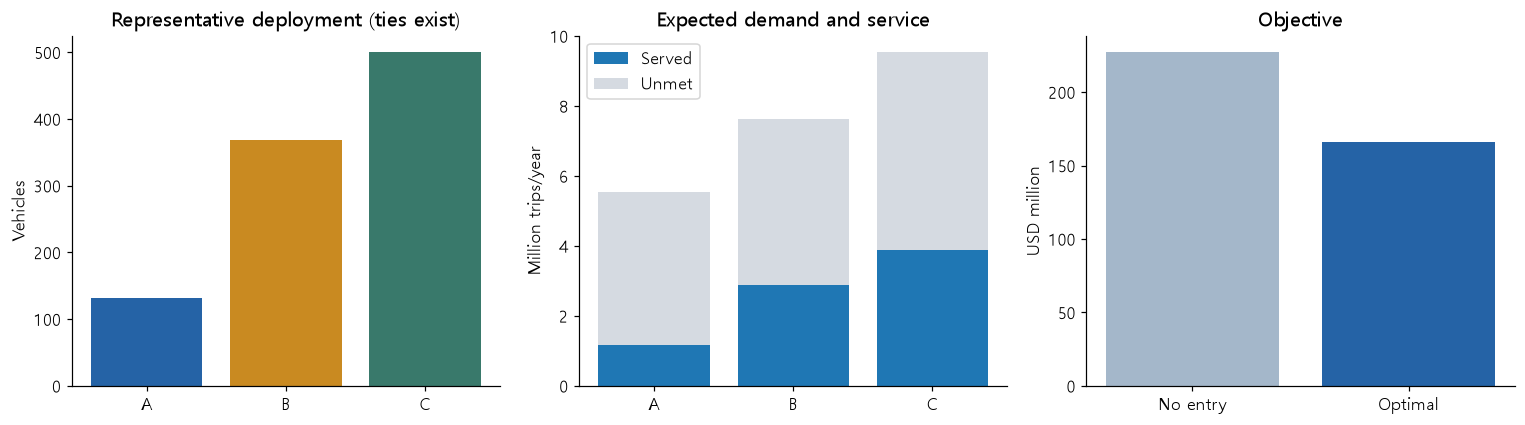

**Baseline:** service rate 34.927%, utilization 90.6%, objective 166,263,859 USD, improvement over no entry 60,854,026 USD. **Optimal allocations: 72: (132, 368, 500), (132, 369, 499), (132, 370, 498), (132, 371, 497), (132, 372, 496), (132, 373, 495), (132, 374, 494), (132, 375, 493), (132, 376, 492), (132, 377, 491), (132, 378, 490), (132, 379, 489).** A representative tied solution does not establish that one city is superior.

With c+=0, the expected net value of one vehicle is c- * kappa * P(demand > allocated capacity) - K. With ten equiprobable scenarios, this probability changes in increments of 0.1. Even if only one scenario has residual demand, one vehicle contributes 8,760 USD, exceeding vehicle cost 7,972 USD. Each city therefore benefits from vehicles up to the largest scenario demand; the fleet limit Q and entry cost F determine the allocation across cities. Compare marginal values and contributions at qbar vehicles in the table above to assess city priorities.

In [6]:
baseline=solve(BASE,'annual baseline');b=baseline['rep']
y=np.array(b['y']);q=np.array(b['q']);capacity=b['capacity']
show('Baseline results',pd.DataFrame([report_row(baseline)]).T.rename(columns={0:'Value'}))
show('Baseline results by city',pd.DataFrame({'City':cities,'Entry':y,'Vehicles':q,'Capacity':capacity,
    'Mean demand':D.mean(axis=0),'Mean served demand':(D-b['U']).mean(axis=0),'Mean unmet demand':b['U'].mean(axis=0),'Mean unused capacity':b['O'].mean(axis=0)}))
show('Baseline totals by scenario',pd.DataFrame({'Scenario':np.arange(1,S+1),'Demand':D.sum(axis=1),
    'Served demand':(D-b['U']).sum(axis=1),'Unmet demand':b['U'].sum(axis=1),'Unused capacity':b['O'].sum(axis=1)}))
ties=baseline['oracle']['samples']
show('All optimal allocations',pd.DataFrame([{'q':qq,**{k:evaluate(BASE,qq)[k] for k in ['cost','served','unused','gain']}} for qq in ties]))
                                                                        
cap_bar=kappa*qbar
served_bar=np.minimum(D,cap_bar).mean(axis=0)
marg_last=c_minus*(np.minimum(D,kappa*q)-np.minimum(D,kappa*np.maximum(q-1,0))).mean(axis=0)-K
marg_next=c_minus*(np.minimum(D,kappa*(q+1))-np.minimum(D,kappa*q)).mean(axis=0)-K
city_value=pd.DataFrame({'City':cities,'Allocation q':q,
    'P(demand > allocated capacity)':(D>capacity).mean(axis=0),
    'Marginal value of the last vehicle (USD)':np.where(q>0,marg_last,np.nan),
    'Marginal value of one more vehicle, ignoring Q (USD)':np.where(q<qbar,marg_next,np.nan),
    'Expected served demand at qbar vehicles':served_bar,
    'Contribution before entry cost at qbar vehicles (USD)':c_minus*served_bar-K*qbar,
    'Contribution after entry cost at qbar vehicles (USD)':c_minus*served_bar-K*qbar-F})
show('Allocation economics by city',city_value)
if SHORTAGE:
    assert baseline['oracle']['count']==3
    assert abs(b['gain']-(Q*(kappa[0]*c_minus[0]-K[0])-2*F[0]))<TOL_USD
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].bar(cities,q,color=COLORS);axes[0].set_ylabel(L('vehicles','Vehicles'));axes[0].set_title(L('Representative allocation (multiple optima)','Representative deployment (ties exist)') if baseline['oracle']['count']>1 else L('Unique optimal allocation','Optimal deployment (unique)'))
axes[1].bar(cities,(D-b['U']).mean(axis=0)/1e6,label=L('Served','Served'))
axes[1].bar(cities,b['U'].mean(axis=0)/1e6,bottom=(D-b['U']).mean(axis=0)/1e6,color='#d5dae1',label=L('Unmet demand','Unmet'))
axes[1].set_ylabel(L('Million trips/year','Million trips/year'));axes[1].legend();axes[1].set_title(L('Expected demand and service','Expected demand and service'))
axes[2].bar([L('No entry','No entry'),L('Optimal','Optimal')],[b['no_entry']/1e6,b['cost']/1e6],color=['#a4b7ca','#2563a6'])
axes[2].set_ylabel('USD million');axes[2].set_title(L('Objective','Objective'))
showfig(fig,'02_baseline')
note(f"**Baseline:** service rate {b['service_rate']:.3%}, utilization {b['utilization']:.1%}, "
     f"objective {b['cost']:,.0f} USD, improvement over no entry {b['gain']:,.0f} USD. "
     f"**Optimal allocations: {baseline['oracle']['count']}: {', '.join(map(str,ties))}.** "
     +('A representative tied solution does not establish that one city is superior.' if baseline['oracle']['count']>1 else 'The unique optimum reflects differences in demand across cities.'))
if SHORTAGE:
    note('Demand exceeds capacity in every city and scenario, so each vehicle serves 8,760 trips regardless of location. '
         'Identical cost, productivity, and margin coefficients imply the same value for any pair of cities.')
else:
    note('With c+=0, the expected net value of one vehicle is c- * kappa * P(demand > allocated capacity) - K. With ten equiprobable scenarios, this probability changes in increments of 0.1. '
         f'Even if only one scenario has residual demand, one vehicle contributes {c_minus[0]*kappa[0]*0.1:,.0f} USD, exceeding vehicle cost {K[0]:,.0f} USD. '
         'Each city therefore benefits from vehicles up to the largest scenario demand; the fleet limit Q and entry cost F determine the allocation across cities. '
         'Compare marginal values and contributions at qbar vehicles in the table above to assess city priorities.')


## 2. Edge cases
Each test starts from a copy of baseline inputs and checks properties appropriate to its scale. E8 is an artificial boundary test rather than a literature-based input setting.

**Edge cases: conditions and checks**

,Test,Condition,Modified input,Expected property,Test result
0,E1,No available vehicles,{'Q': 0},"All q=0, U=D, Z=Z0",PASS
1,E2,Zero demand,"{'M': array([0., 0., 0.])}","No entry, Z=0, O=U=0",PASS
2,E3,Allocation to A prohibited,"{'qbar': array([ 0, 500, 500])}",A=0; B and C are locally optimal under a one-v...,PASS
3,E4,Zero unmet demand penalty,"{'c_minus': array([0., 0., 0.])}","No entry, Z=0",PASS
4,E5,Very high entry cost,"{'F': array([2.27117886e+08, 2.27117886e+08, 2...",Entry cost exceeds total service value; no entry,PASS
5,E6,Relaxed total fleet limit,{'Q': 2000},"Nonbinding Q: total <= 1,500 vehicles, improve...",PASS
6,E7,Zero entry cost,"{'F': array([0., 0., 0.])}",Improvement >= baseline; total <= Q,PASS
7,E8,Demand equals one vehicle capacity,"{'p': array([[1.51581193e-05, 1.13685895e-05, ...","Set F=0 to permit entry; one vehicle per city,...",PASS


**Edge cases: allocations and service**

,Test,Representative allocation,Number of optimal q vectors,Service rate (%),Mean served demand,Mean unmet demand,Mean unused capacity
0,E1,"(0, 0, 0)",1,0.000000,0.000000e+00,2.271179e+07,0.000
1,E2,"(0, 0, 0)",1,NaN,0.000000e+00,0.000000e+00,0.000
2,E3,"(0, 500, 500)",1,33.213174,7.543306e+06,1.516848e+07,1216694.064
3,E4,"(0, 0, 0)",1,0.000000,0.000000e+00,2.271179e+07,0.000
4,E5,"(0, 0, 0)",1,0.000000,0.000000e+00,2.271179e+07,0.000
5,E6,"(500, 500, 500)",1,46.926991,1.065796e+07,1.205383e+07,2482041.096
6,E7,"(132, 368, 500)",72,34.927247,7.932603e+06,1.477919e+07,827397.411
7,E8,"(1, 1, 1)",1,100.000000,2.628000e+04,0.000000e+00,0.000


**Edge cases: cost breakdown (USD)**

,Test,Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement
0,E1,0.0,0.0,0.0,2.271179e+08,2.271179e+08,2.271179e+08,0.00
1,E2,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.00
2,E3,7000000.0,7972000.0,0.0,1.516848e+08,1.666568e+08,2.271179e+08,60461059.36
3,E4,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.00
4,E5,0.0,0.0,0.0,2.271179e+08,2.271179e+08,2.271179e+08,0.00
5,E6,10500000.0,11958000.0,0.0,1.205383e+08,1.429963e+08,2.271179e+08,84121589.04
6,E7,0.0,7972000.0,0.0,1.477919e+08,1.557639e+08,2.271179e+08,71354025.89
7,E8,0.0,23916.0,0.0,0.000000e+00,2.391600e+04,2.628000e+05,238884.00


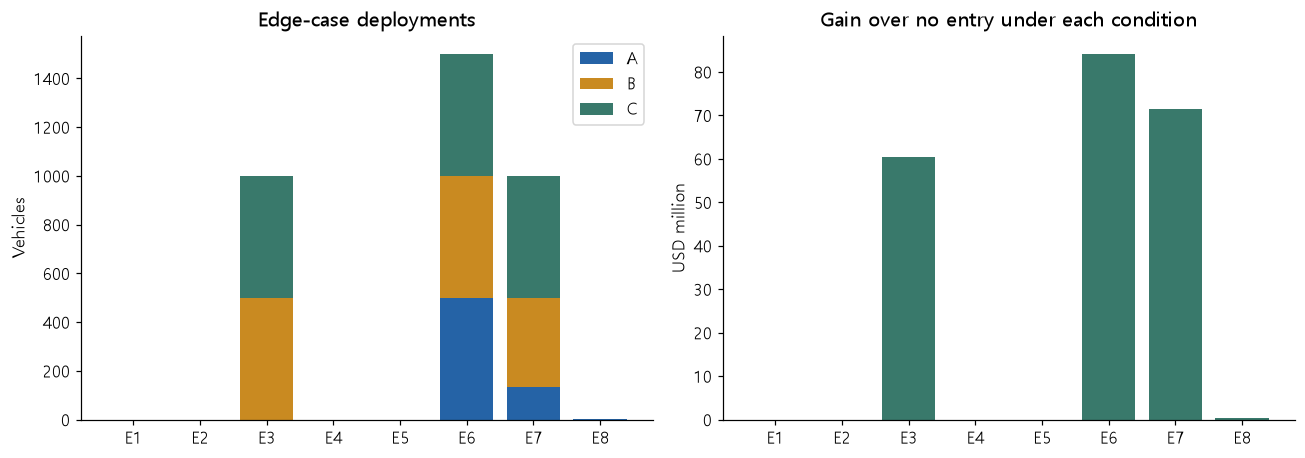

If F remained USD 3.5 million in E8, one vehicle could not recover the entry cost, and no entry would be optimal. The demand-capacity equality test explicitly sets F=0.

In [7]:
edge_specs=[
 ('E1','No available vehicles',{'Q':0},'All q=0, U=D, Z=Z0'),
 ('E2','Zero demand',{'M':np.zeros(3)},'No entry, Z=0, O=U=0'),
 ('E3','Allocation to A prohibited',{'qbar':np.array([0,500,500])},'A=0; B and C are locally optimal under a one-vehicle change'),
 ('E4','Zero unmet demand penalty',{'c_minus':np.zeros(3)},'No entry, Z=0'),
 ('E5','Very high entry cost',{'F':np.full(3,b['no_entry']+1)},'Entry cost exceeds total service value; no entry'),
 ('E6','Relaxed total fleet limit',{'Q':2000},'Nonbinding Q: total <= 1,500 vehicles, improvement >= baseline, local optimality'),
 ('E7','Zero entry cost',{'F':np.zeros(3)},'Improvement >= baseline; total <= Q'),
 ('E8','Demand equals one vehicle capacity',{'p':np.tile(BASE['kappa']/BASE['M'],(3,1)),'F':np.zeros(3)},
  'Set F=0 to permit entry; one vehicle per city, O=U=0')]
def locally_optimal(d,r):
                                                           
    qq=np.array(r['q']);best=r['gain']
    for cc in range(3):
        for step in (-1,1):
            q2=qq.copy();q2[cc]+=step
            if q2[cc]<0 or q2[cc]>d['qbar'][cc] or q2.sum()>d['Q']:continue
            if evaluate(d,q2)['gain']>best+TOL_USD:return False
    return True
edge_answers={};edge_rows=[]
for case,title,changes,expected in edge_specs:
    d=deepcopy(BASE);d.update(deepcopy(changes));a=solve(d,case);r=a['rep'];o=a['oracle']
    if case in ['E1','E2','E4','E5']:ok=np.all(o['q_max']==0)
    elif case=='E3':ok=o['q_min'][0]==0 and o['q_max'][0]==0 and locally_optimal(d,r)
    elif case=='E6':ok=sum(r['q'])<=int(d['qbar'].sum()) and r['gain']>=b['gain']-TOL_USD and locally_optimal(d,r)
    elif case=='E7':ok=r['gain']>=b['gain']-TOL_USD and sum(r['q'])<=d['Q']
    else:ok=np.array_equal(o['q_min'],[1,1,1]) and np.array_equal(o['q_max'],[1,1,1]) and r['unused']==0 and r['unmet']==0
    if case=='E1':ok=ok and abs(r['cost']-r['no_entry'])<TOL_USD
    if case in ['E2','E4']:ok=ok and abs(r['cost'])<TOL_USD
    assert ok,(case,r)
    edge_answers[case]=a
    edge_rows.append({'Test':case,'Condition':title,'Modified input':str(changes),'Expected property':expected,'Test result':'PASS',**report_row(a)})
edge_table=pd.DataFrame(edge_rows)
show('Edge cases: conditions and checks',edge_table[['Test','Condition','Modified input','Expected property','Test result']])
show('Edge cases: allocations and service',edge_table[['Test','Representative allocation','Number of optimal q vectors','Service rate (%)','Mean served demand','Mean unmet demand','Mean unused capacity']])
show('Edge cases: cost breakdown (USD)',edge_table[['Test','Entry cost','Vehicle cost','Idle penalty','Unmet demand loss','Objective','No-entry baseline','Improvement']])
fig,axes=plt.subplots(1,2,figsize=(12,4.3));bottom=np.zeros(8)
for cc in range(3):
    vals=[a['rep']['q'][cc] for a in edge_answers.values()]
    axes[0].bar(list(edge_answers),vals,bottom=bottom,color=COLORS[cc],label=cities[cc]);bottom+=vals
axes[0].legend();axes[0].set_ylabel(L('vehicles','Vehicles'));axes[0].set_title(L('Representative edge-case allocations','Edge-case deployments'))
axes[1].bar(list(edge_answers),[a['rep']['gain']/1e6 for a in edge_answers.values()],color='#39796b')
axes[1].set_ylabel('USD million');axes[1].set_title(L('Improvement over no entry under each condition','Gain over no entry under each condition'))
showfig(fig,'03_edges')
note('If F remained USD 3.5 million in E8, one vehicle could not recover the entry cost, and no entry would be optimal. '
     'The demand-capacity equality test explicitly sets F=0.')


## 3. Sensitivity analysis
### 3-1. Common parameter changes
Change one input at a time, including reference comparison values and intermediate settings. Changes in F, K, kappa, c+, c-, and qbar apply simultaneously to all cities. The common M multiplier preserves the city ratios 0.75:1:1.25; the p multiplier scales the full fixed probability matrix. M_A and city-specific analyses change only one city.

Allocation lines show the representative optimum; shading shows each city's range across all optimal q vectors. Costs and service rates refer to the representative solution. Read service, service rates, and improvement together when comparing different input settings.


In [8]:
experiments={};sensitivity_tables={}
def run_sweep(name,values,change):
    results=[]
    for value in values:
        d=deepcopy(BASE);change(d,float(value));a=solve(d,f'{name}={value:g}');results.append((float(value),a))
    experiments[name]=results
    table=pd.DataFrame([{'Input value':v,**report_row(a)} for v,a in results])
    table['Change in served demand from baseline']=table['Mean served demand']-b['served']
    table['Change in service rate (pp)']=table['Service rate (%)']-100*b['service_rate']
    table['Change in objective from baseline']=table['Objective']-b['cost']
    table['Change in improvement from baseline']=table['Improvement']-b['gain']
    sensitivity_tables[name]=table;return results

def plot_sweep(name,results,xlabel,divisor=1):
    xx=np.array([v for v,a in results])/divisor;rr=[a['rep'] for v,a in results]
    fig,axes=plt.subplots(2,2,figsize=(13,8))
    for c in range(3):
        axes[0,0].plot(xx,[r['q'][c] for r in rr],color=COLORS[c],marker=['o','s','^'][c],linestyle=['-','--',':'][c],label=cities[c])
        axes[0,0].fill_between(xx,[a['oracle']['q_min'][c] for v,a in results],[a['oracle']['q_max'][c] for v,a in results],color=COLORS[c],alpha=.09)
    axes[0,0].legend(ncols=3);axes[0,0].set_ylim(bottom=0);axes[0,0].set_ylabel(L('vehicles','Vehicles'))
    axes[0,0].set_title(L('1. Representative allocation and optimal ranges','1. Representative deployment and ranges over ties'))
    axes[0,1].plot(xx,[100*r['service_rate'] for r in rr],marker='o',color='#2563a6')
    axes[0,1].set_ylim(bottom=0);axes[0,1].set_ylabel('%');axes[0,1].set_title(L('2. Overall service rate','2. Share of total demand served'))
    compnames=[L('Entry cost','Entry'),L('Vehicle cost','Vehicle'),L('Idle penalty','Idle'),L('Unmet demand loss','Unmet')]
    for j in range(4):axes[1,0].plot(xx,[r['components'][j]/1e6 for r in rr],linestyle=['-','--',':','-.'][j],label=compnames[j])
    axes[1,0].plot(xx,[r['cost']/1e6 for r in rr],color='black',label=L('Total','Total'))
    axes[1,0].set_ylim(bottom=0);axes[1,0].legend(ncols=2,fontsize=9);axes[1,0].set_ylabel('USD million')
    axes[1,0].set_title(L('3. Objective and cost breakdown','3. Objective and components'))
    axes[1,1].plot(xx,[r['gain']/1e6 for r in rr],marker='o',color='#39796b');axes[1,1].set_ylim(bottom=0)
    axes[1,1].set_ylabel('USD million');axes[1,1].set_title(L('4. Improvement over no entry','4. Gain over no entry in the same setting'))
    for ax in axes.flat:ax.set_xlabel(xlabel);ax.grid(alpha=.15)
    fig.suptitle(name);fig.subplots_adjust(top=.92)
    showfig(fig,'sweep_'+name.replace(' ','_').replace('+','plus'))
    t=sensitivity_tables[name]
    show(name+': selected comparisons',t[['Input value','Representative allocation','Number of optimal q vectors','Service rate (%)','Mean unused capacity','Objective','Improvement']].round(4))
    detail('Full results: service, costs, and changes from baseline',t)
    changed=[]
    for (v0,a0),(v1,a1) in zip(results,results[1:]):
        signature=lambda a:(a['oracle']['count'],tuple(a['oracle']['q_min']),tuple(a['oracle']['q_max']),a['oracle']['q'])
        if signature(a0)!=signature(a1):changed.append(f'{v0:g} → {v1:g}')
    note('**Sampled intervals with a change in the optimal allocation set:** '+(', '.join(changed) if changed else 'The allocation-set summary is unchanged over the sampled range')+
         '. These intervals do not identify exact switching thresholds without further evaluation.')

sweep_specs=[
 ('Q',sorted(set(range(0,2001,100))),lambda d,v:d.update(Q=int(v)),L('Total fleet limit (vehicles)','Fleet limit'),1),
 ('F',F[0]*np.linspace(.75,1.25,9),lambda d,v:d.update(F=np.full(3,v)),L('Entry cost per city (million USD)','Entry cost (USD million)'),1e6),
 ('K',K[0]*np.linspace(.75,1.25,9),lambda d,v:d.update(K=np.full(3,v)),L('Vehicle cost (USD/vehicle/year)','Vehicle cost (USD/vehicle-year)'),1),
 ('kappa',kappa[0]*np.linspace(.75,1.25,9),lambda d,v:d.update(kappa=np.full(3,v)),L('trips/vehicle/year','Trips/vehicle-year'),1),
 ('M_multiplier',np.linspace(.75,1.25,9),lambda d,v:d.update(M=BASE['M']*v),L('Market size multiplier (city ratios preserved)','Multiplier on all M (ratios kept)'),1),
 ('qbar',[100,250,500,750,1000,1500],lambda d,v:d.update(qbar=np.full(3,int(v))),L('Vehicle limit per city','City vehicle cap'),1),
 ('c_plus',[0,1,3,5,10,15,40],lambda d,v:d.update(c_plus=np.full(3,v)),L('USD/unused capacity trip','USD/unused trip capacity'),1),
 ('c_minus',[2,5,10,15,20],lambda d,v:d.update(c_minus=np.full(3,v)),L('USD/unmet trip','USD/unserved trip'),1),
 ('p_multiplier',[.75,1,1.25],lambda d,v:d.update(p=BASE['p']*v),L('Choice probability multiplier, all cities','Multiplier on all choice probabilities'),1),
 ('M_A_multiplier',np.linspace(.75,1.25,9),lambda d,v:d['M'].__setitem__(0,BASE['M'][0]*v),L('Market size multiplier for A','Multiplier on A market size'),1),
 ('alpha',np.linspace(0,1,11),lambda d,v:d.update(p=BASE['p'].mean(axis=0)+v*(BASE['p']-BASE['p'].mean(axis=0))),L('Demand variability multiplier, mean preserved','Mean-preserving demand spread'),1)]
show('Parameter ranges (all other inputs held at baseline)',pd.DataFrame([{
    'Input':name,'Minimum':float(min(vals)),'Maximum':float(max(vals)),'Number of settings':len(vals),
    'Scope':'A only' if name=='M_A_multiplier' else ('Total limit' if name=='Q' else 'All cities'),
    'Range basis':'Additional design: probability scale and variability' if name in ['p_multiplier','alpha'] else ('Reference values 0, 1, 3, 5; additional values 10, 15, 20' if name=='c_plus' else ('Reference +/-25% range applied to city market sizes' if name=='M_multiplier' else 'Includes reference comparison values'))}
    for name,vals,change,xlabel,divisor in sweep_specs]))

**Parameter ranges (all other inputs held at baseline)**

,Input,Minimum,Maximum,Number of settings,Scope,Range basis
0,Q,0.00,2000.00,21,Total limit,Includes reference comparison values
1,F,2625000.00,4375000.00,9,All cities,Includes reference comparison values
2,K,5979.00,9965.00,9,All cities,Includes reference comparison values
3,kappa,6570.00,10950.00,9,All cities,Includes reference comparison values
4,M_multiplier,0.75,1.25,9,All cities,Reference +/-25% range applied to city market ...
5,qbar,100.00,1500.00,6,All cities,Includes reference comparison values
6,c_plus,0.00,40.00,7,All cities,"Reference values 0, 1, 3, 5; additional values..."
7,c_minus,2.00,20.00,5,All cities,Includes reference comparison values
8,p_multiplier,0.75,1.25,3,All cities,Additional design: probability scale and varia...
9,M_A_multiplier,0.75,1.25,9,A only,Includes reference comparison values


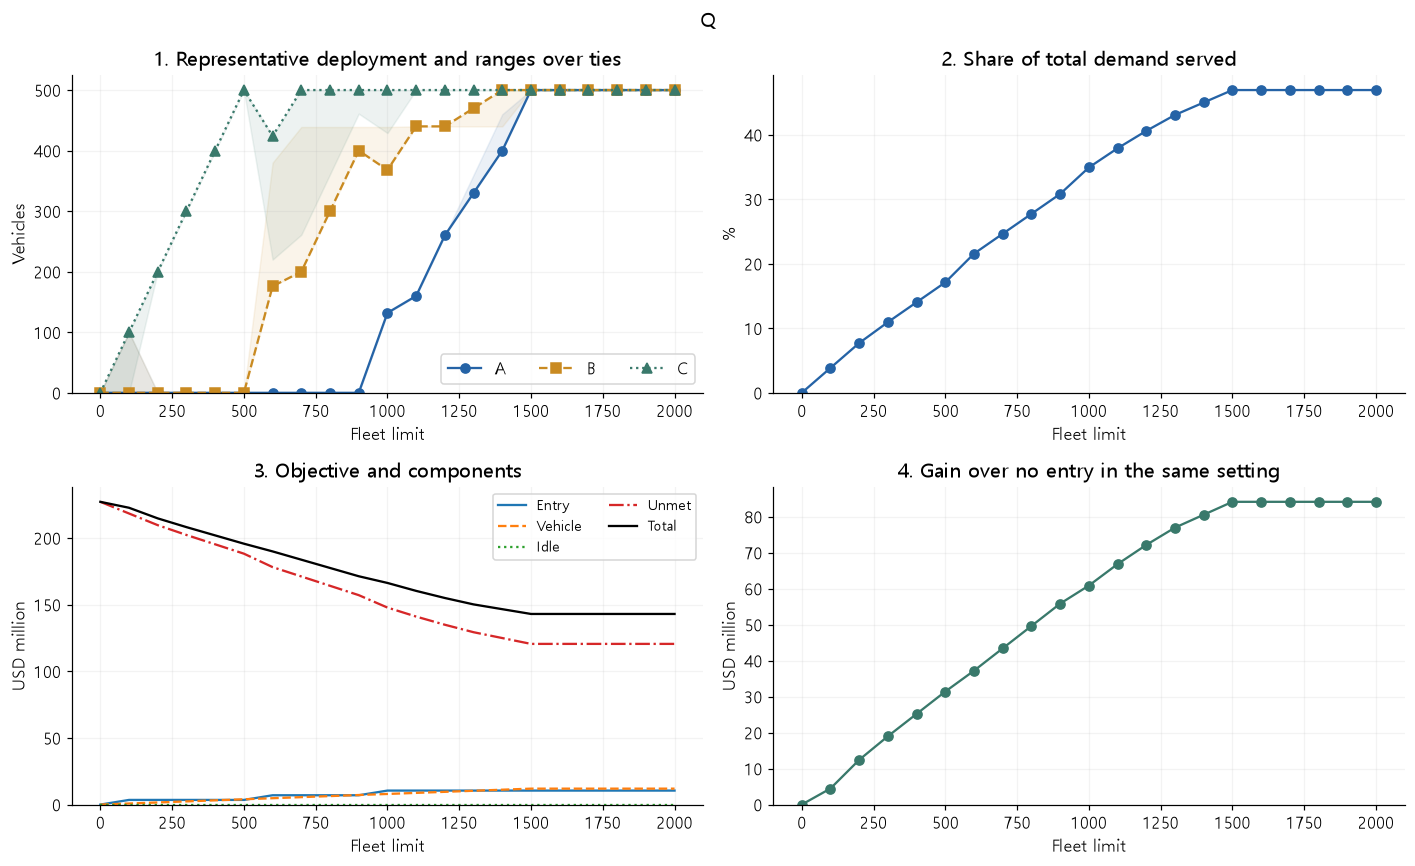

**Q: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,0.0,"(0, 0, 0)",1,0.0000,0.000,2.271179e+08,0.00
1,100.0,"(0, 0, 100)",3,3.8570,0.000,2.226551e+08,4462800.00
2,200.0,"(0, 0, 200)",1,7.7141,0.000,2.146923e+08,12425600.00
3,300.0,"(0, 0, 300)",1,10.9532,140327.930,2.081328e+08,18985120.70
4,400.0,"(0, 0, 400)",1,14.0388,315527.930,2.019220e+08,25195920.70
5,500.0,"(0, 0, 500)",1,17.1245,490727.930,1.957112e+08,31406720.70
6,600.0,"(0, 176, 424)",205,21.5672,357710.274,1.899182e+08,37199697.26
7,700.0,"(0, 200, 500)",240,24.6528,532910.274,1.837074e+08,43410497.26
8,800.0,"(0, 300, 500)",140,27.7384,708110.274,1.774966e+08,49621297.26
9,900.0,"(0, 400, 500)",40,30.8240,883310.274,1.712858e+08,55832097.26


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
0.0000,"(0, 0, 0)",1,"22,711,788.5265",0.0000,"22,711,788.5265",0.0000,0.0000,NaN,0.0000,0.0000,0.0000,"227,117,885.2650","227,117,885.2650","227,117,885.2650",0.0000,"(0, 0, 0)","(0, 0, 0)","-7,932,602.5890",-34.9272,"60,854,025.8900","-60,854,025.8900"
100.0000,"(0, 0, 100)",3,"22,711,788.5265","876,000.0000","21,835,788.5265",0.0000,3.8570,100.0000,"3,500,000.0000","797,200.0000",0.0000,"218,357,885.2650","222,655,085.2650","227,117,885.2650","4,462,800.0000","(0, 0, 0)","(100, 100, 100)","-7,056,602.5890",-31.0702,"56,391,225.8900","-56,391,225.8900"
200.0000,"(0, 0, 200)",1,"22,711,788.5265","1,752,000.0000","20,959,788.5265",0.0000,7.7141,100.0000,"3,500,000.0000","1,594,400.0000",0.0000,"209,597,885.2650","214,692,285.2650","227,117,885.2650","12,425,600.0000","(0, 0, 200)","(0, 0, 200)","-6,180,602.5890",-27.2132,"48,428,425.8900","-48,428,425.8900"
300.0000,"(0, 0, 300)",1,"22,711,788.5265","2,487,672.0700","20,224,116.4565","140,327.9300",10.9532,94.6603,"3,500,000.0000","2,391,600.0000",0.0000,"202,241,164.5650","208,132,764.5650","227,117,885.2650","18,985,120.7000","(0, 0, 300)","(0, 0, 300)","-5,444,930.5190",-23.9740,"41,868,905.1900","-41,868,905.1900"
400.0000,"(0, 0, 400)",1,"22,711,788.5265","3,188,472.0700","19,523,316.4565","315,527.9300",14.0388,90.9952,"3,500,000.0000","3,188,800.0000",0.0000,"195,233,164.5650","201,921,964.5650","227,117,885.2650","25,195,920.7000","(0, 0, 400)","(0, 0, 400)","-4,744,130.5190",-20.8884,"35,658,105.1900","-35,658,105.1900"
500.0000,"(0, 0, 500)",1,"22,711,788.5265","3,889,272.0700","18,822,516.4565","490,727.9300",17.1245,88.7962,"3,500,000.0000","3,986,000.0000",0.0000,"188,225,164.5650","195,711,164.5650","227,117,885.2650","31,406,720.7000","(0, 0, 500)","(0, 0, 500)","-4,043,330.5190",-17.8028,"29,447,305.1900","-29,447,305.1900"
600.0000,"(0, 176, 424)",205,"22,711,788.5265","4,898,289.7260","17,813,498.8005","357,710.2740",21.5672,93.1942,"7,000,000.0000","4,783,200.0000",0.0000,"178,134,988.0050","189,918,188.0050","227,117,885.2650","37,199,697.2600","(0, 176, 220)","(0, 380, 424)","-3,034,312.8630",-13.3601,"23,654,328.6300","-23,654,328.6300"
700.0000,"(0, 200, 500)",240,"22,711,788.5265","5,599,089.7260","17,112,698.8005","532,910.2740",24.6528,91.3094,"7,000,000.0000","5,580,400.0000",0.0000,"171,126,988.0050","183,707,388.0050","227,117,885.2650","43,410,497.2600","(0, 200, 261)","(0, 439, 500)","-2,333,512.8630",-10.2745,"17,443,528.6300","-17,443,528.6300"
800.0000,"(0, 300, 500)",140,"22,711,788.5265","6,299,889.7260","16,411,898.8005","708,110.2740",27.7384,89.8957,"7,000,000.0000","6,377,600.0000",0.0000,"164,118,988.0050","177,496,588.0050","227,117,885.2650","49,621,297.2600","(0, 300, 361)","(0, 439, 500)","-1,632,712.8630",-7.1888,"11,232,728.6300","-11,232,728.6300"
900.0000,"(0, 400, 500)",40,"22,711,788.5265","7,000,689.7260","15,711,098.8005","883,310.2740",30.8240,88.7962,"7,000,000.0000","7,174,800.0000",0.0000,"157,110,988.0050","171,285,788.0050","227,117,885.2650","55,832,097.2600","(0, 400, 461)","(0, 439, 500)","-931,912.8630",-4.1032,"5,021,928.6300","-5,021,928.6300"


**Sampled intervals with a change in the optimal allocation set:** 0 → 100, 100 → 200, 200 → 300, 300 → 400, 400 → 500, 500 → 600, 600 → 700, 700 → 800, 800 → 900, 900 → 1000, 1000 → 1100, 1100 → 1200, 1200 → 1300, 1300 → 1400, 1400 → 1500. These intervals do not identify exact switching thresholds without further evaluation.

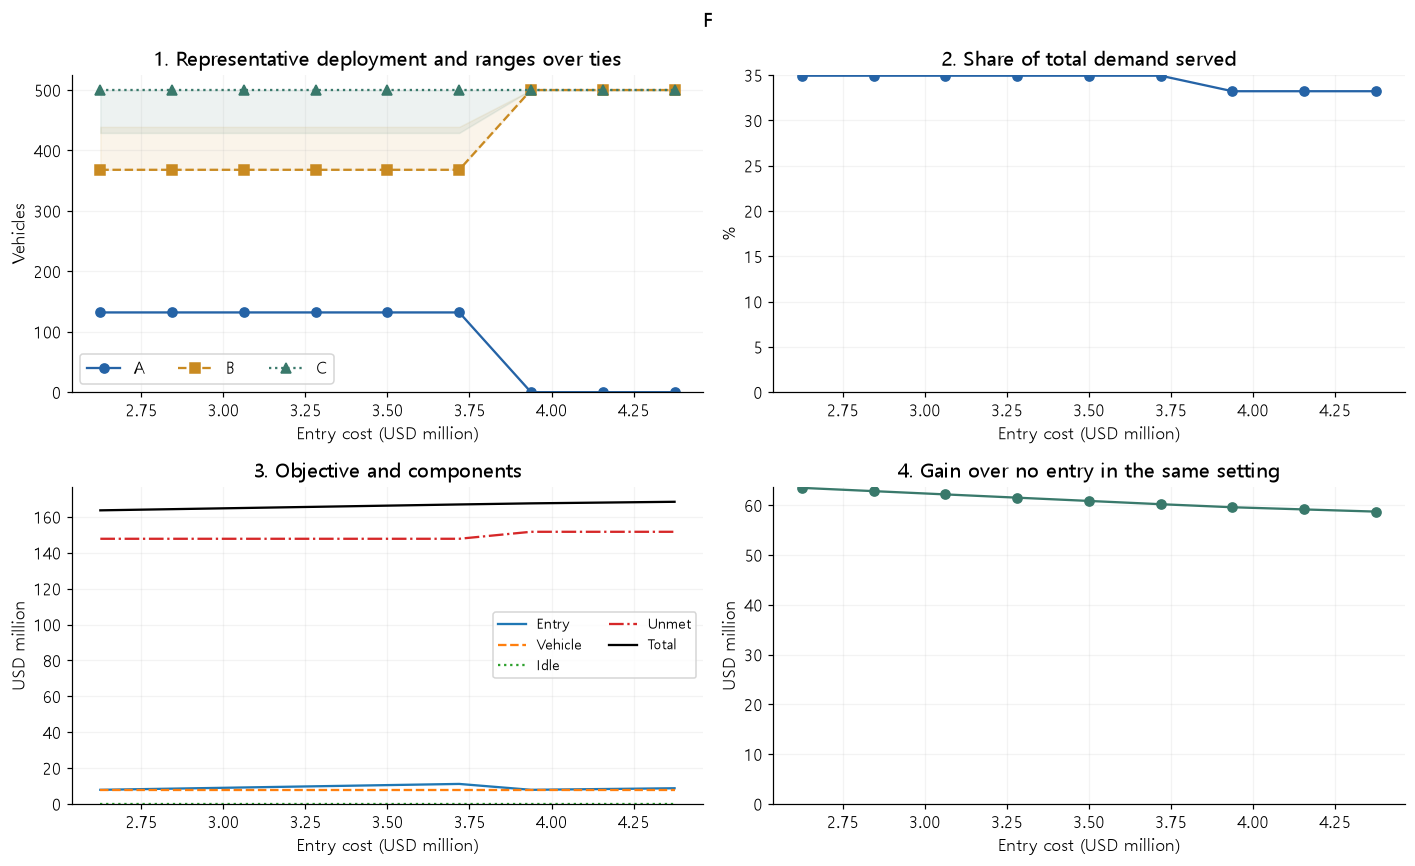

**F: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,2625000.0,"(132, 368, 500)",72,34.9272,827397.411,1.636389e+08,63479025.89
1,2843750.0,"(132, 368, 500)",72,34.9272,827397.411,1.642951e+08,62822775.89
2,3062500.0,"(132, 368, 500)",72,34.9272,827397.411,1.649514e+08,62166525.89
3,3281250.0,"(132, 368, 500)",72,34.9272,827397.411,1.656076e+08,61510275.89
4,3500000.0,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,60854025.89
5,3718750.0,"(132, 368, 500)",72,34.9272,827397.411,1.669201e+08,60197775.89
6,3937500.0,"(0, 500, 500)",1,33.2132,1216694.064,1.675318e+08,59586059.36
7,4156250.0,"(0, 500, 500)",1,33.2132,1216694.064,1.679693e+08,59148559.36
8,4375000.0,"(0, 500, 500)",1,33.2132,1216694.064,1.684068e+08,58711059.36


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
"2,625,000.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"7,875,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","163,638,859.3750","227,117,885.2650","63,479,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-2,625,000.0000","2,625,000.0000"
"2,843,750.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"8,531,250.0000","7,972,000.0000",0.0000,"147,791,859.3750","164,295,109.3750","227,117,885.2650","62,822,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,968,750.0000","1,968,750.0000"
"3,062,500.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"9,187,500.0000","7,972,000.0000",0.0000,"147,791,859.3750","164,951,359.3750","227,117,885.2650","62,166,525.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,312,500.0000","1,312,500.0000"
"3,281,250.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"9,843,750.0000","7,972,000.0000",0.0000,"147,791,859.3750","165,607,609.3750","227,117,885.2650","61,510,275.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-656,250.0000","656,250.0000"
"3,500,000.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
"3,718,750.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"11,156,250.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,920,109.3750","227,117,885.2650","60,197,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"656,250.0000","-656,250.0000"
"3,937,500.0000","(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"7,875,000.0000","7,972,000.0000",0.0000,"151,684,825.9050","167,531,825.9050","227,117,885.2650","59,586,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"1,267,966.5300","-1,267,966.5300"
"4,156,250.0000","(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"8,312,500.0000","7,972,000.0000",0.0000,"151,684,825.9050","167,969,325.9050","227,117,885.2650","59,148,559.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"1,705,466.5300","-1,705,466.5300"
"4,375,000.0000","(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"8,750,000.0000","7,972,000.0000",0.0000,"151,684,825.9050","168,406,825.9050","227,117,885.2650","58,711,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"2,142,966.5300","-2,142,966.5300"


**Sampled intervals with a change in the optimal allocation set:** 3.71875e+06 → 3.9375e+06. These intervals do not identify exact switching thresholds without further evaluation.

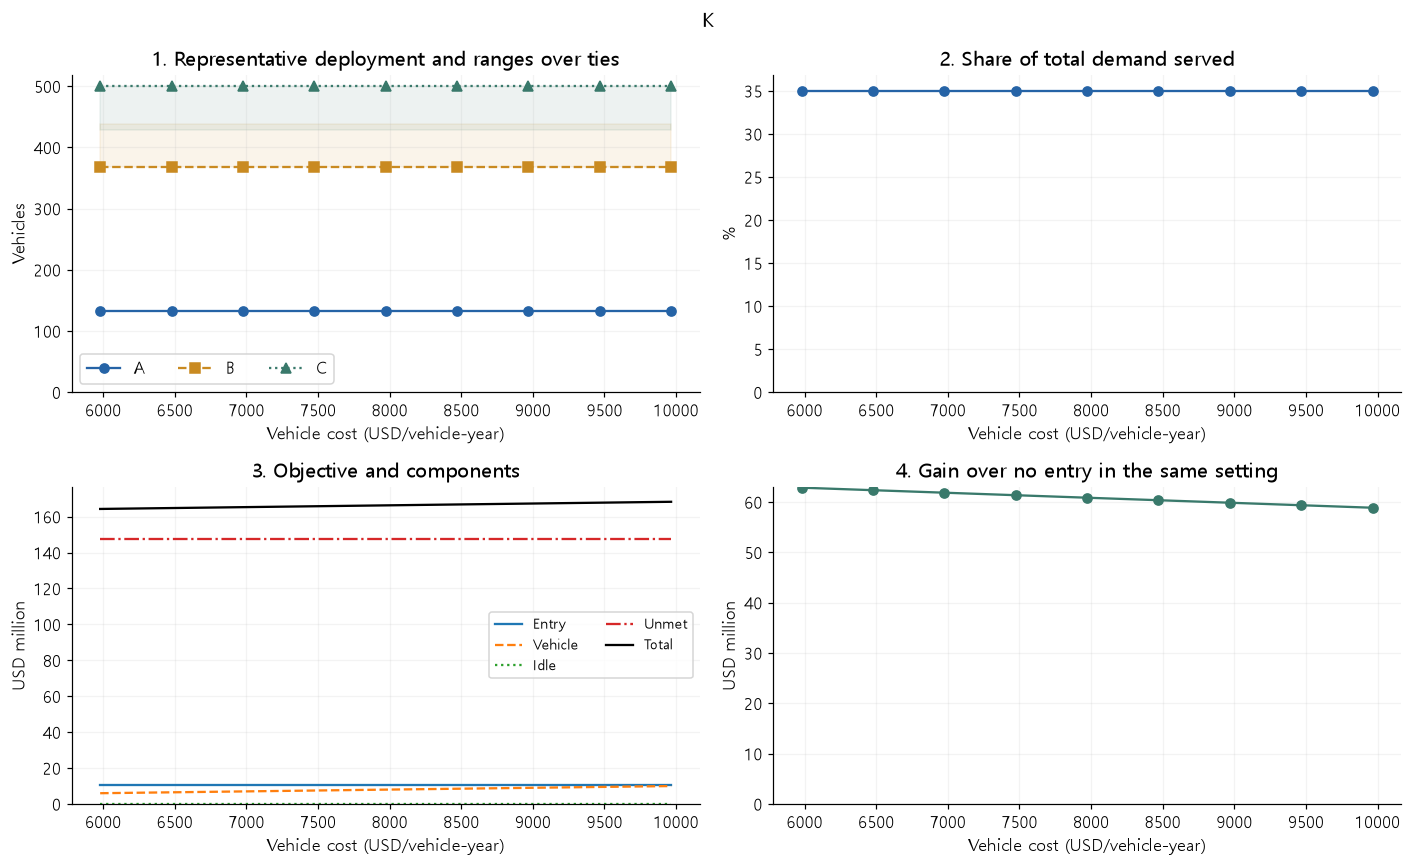

**K: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,5979.00,"(132, 368, 500)",72,34.9272,827397.411,1.642709e+08,62847025.89
1,6477.25,"(132, 368, 500)",72,34.9272,827397.411,1.647691e+08,62348775.89
2,6975.50,"(132, 368, 500)",72,34.9272,827397.411,1.652674e+08,61850525.89
3,7473.75,"(132, 368, 500)",72,34.9272,827397.411,1.657656e+08,61352275.89
4,7972.00,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,60854025.89
5,8470.25,"(132, 368, 500)",72,34.9272,827397.411,1.667621e+08,60355775.89
6,8968.50,"(132, 368, 500)",72,34.9272,827397.411,1.672604e+08,59857525.89
7,9466.75,"(132, 368, 500)",72,34.9272,827397.411,1.677586e+08,59359275.89
8,9965.00,"(132, 368, 500)",72,34.9272,827397.411,1.682569e+08,58861025.89


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
"5,979.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","5,979,000.0000",0.0000,"147,791,859.3750","164,270,859.3750","227,117,885.2650","62,847,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,993,000.0000","1,993,000.0000"
"6,477.2500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","6,477,250.0000",0.0000,"147,791,859.3750","164,769,109.3750","227,117,885.2650","62,348,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,494,750.0000","1,494,750.0000"
"6,975.5000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","6,975,500.0000",0.0000,"147,791,859.3750","165,267,359.3750","227,117,885.2650","61,850,525.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-996,500.0000","996,500.0000"
"7,473.7500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,473,750.0000",0.0000,"147,791,859.3750","165,765,609.3750","227,117,885.2650","61,352,275.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-498,250.0000","498,250.0000"
"7,972.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
"8,470.2500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","8,470,250.0000",0.0000,"147,791,859.3750","166,762,109.3750","227,117,885.2650","60,355,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"498,250.0000","-498,250.0000"
"8,968.5000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","8,968,500.0000",0.0000,"147,791,859.3750","167,260,359.3750","227,117,885.2650","59,857,525.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"996,500.0000","-996,500.0000"
"9,466.7500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","9,466,750.0000",0.0000,"147,791,859.3750","167,758,609.3750","227,117,885.2650","59,359,275.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"1,494,750.0000","-1,494,750.0000"
"9,965.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","9,965,000.0000",0.0000,"147,791,859.3750","168,256,859.3750","227,117,885.2650","58,861,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"1,993,000.0000","-1,993,000.0000"


**Sampled intervals with a change in the optimal allocation set:** The allocation-set summary is unchanged over the sampled range. These intervals do not identify exact switching thresholds without further evaluation.

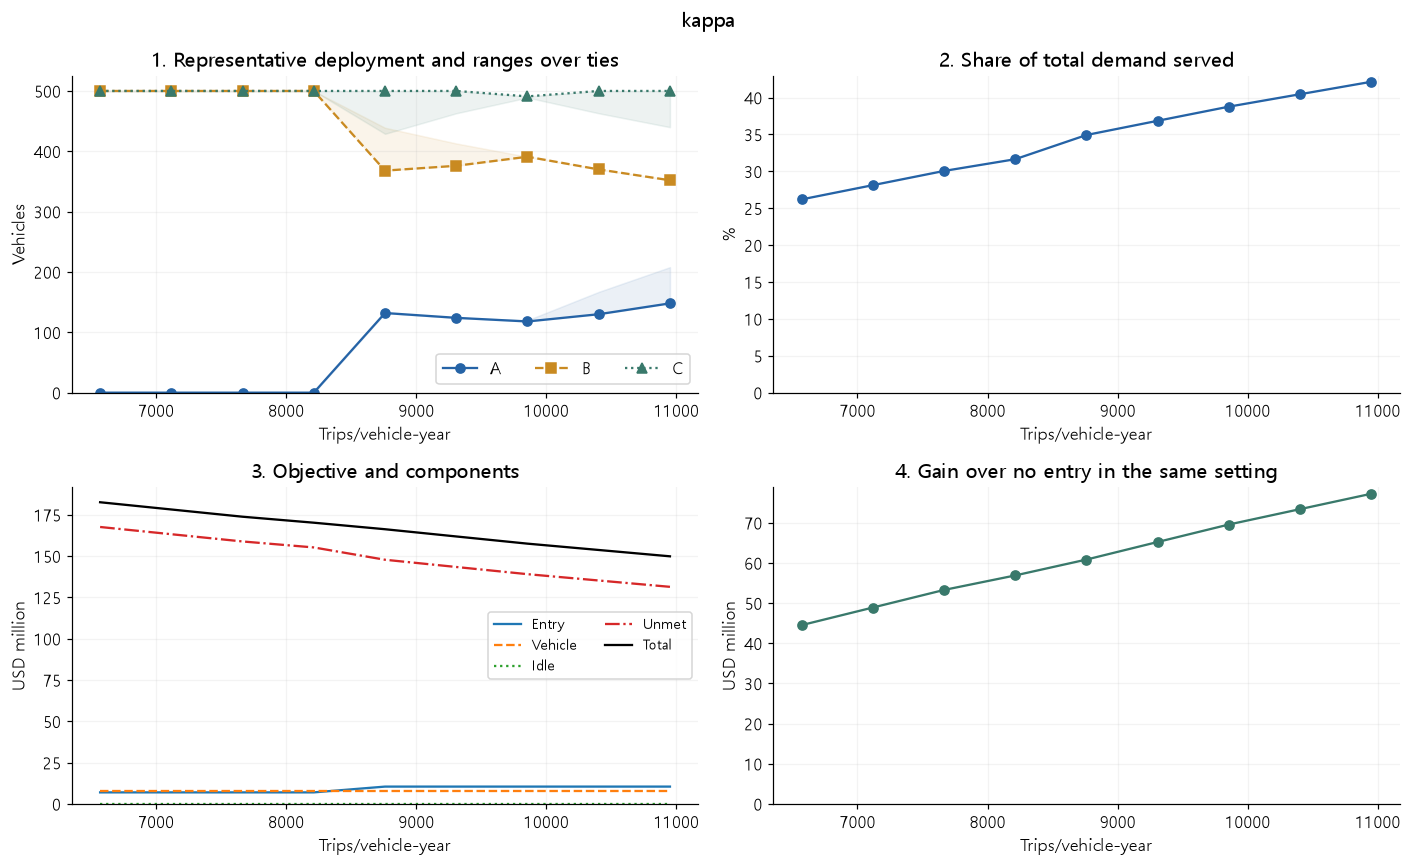

**kappa: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,6570.0,"(0, 500, 500)",1,26.1956,6.205103e+05,1.825950e+08,4.452290e+07
1,7117.5,"(0, 500, 500)",1,28.1241,7.300103e+05,1.782150e+08,4.890290e+07
2,7665.0,"(0, 500, 500)",1,30.0526,8.395103e+05,1.738350e+08,5.328290e+07
3,8212.5,"(0, 500, 500)",1,31.6463,1.025069e+06,1.702156e+08,5.690231e+07
4,8760.0,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
5,9307.5,"(124, 376, 500)",38,36.8545,9.371843e+05,1.618867e+08,6.523116e+07
6,9855.0,"(118, 391, 491)",3,38.7705,1.049520e+06,1.575351e+08,6.958280e+07
7,10402.5,"(130, 370, 500)",38,40.4568,1.214033e+06,1.537052e+08,7.341267e+07
8,10950.0,"(148, 352, 500)",61,42.1445,1.378239e+06,1.498723e+08,7.724561e+07


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
"6,570.0000","(0, 500, 500)",1,"22,711,788.5265","5,949,489.7260","16,762,298.8005","620,510.2740",26.1956,90.5554,"7,000,000.0000","7,972,000.0000",0.0000,"167,622,988.0050","182,594,988.0050","227,117,885.2650","44,522,897.2600","(0, 500, 500)","(0, 500, 500)","-1,983,112.8630",-8.7316,"16,331,128.6300","-16,331,128.6300"
"7,117.5000","(0, 500, 500)",1,"22,711,788.5265","6,387,489.7260","16,324,298.8005","730,010.2740",28.1241,89.7434,"7,000,000.0000","7,972,000.0000",0.0000,"163,242,988.0050","178,214,988.0050","227,117,885.2650","48,902,897.2600","(0, 500, 500)","(0, 500, 500)","-1,545,112.8630",-6.8031,"11,951,128.6300","-11,951,128.6300"
"7,665.0000","(0, 500, 500)",1,"22,711,788.5265","6,825,489.7260","15,886,298.8005","839,510.2740",30.0526,89.0475,"7,000,000.0000","7,972,000.0000",0.0000,"158,862,988.0050","173,834,988.0050","227,117,885.2650","53,282,897.2600","(0, 500, 500)","(0, 500, 500)","-1,107,112.8630",-4.8746,"7,571,128.6300","-7,571,128.6300"
"8,212.5000","(0, 500, 500)",1,"22,711,788.5265","7,187,430.9360","15,524,357.5905","1,025,069.0640",31.6463,87.5182,"7,000,000.0000","7,972,000.0000",0.0000,"155,243,575.9050","170,215,575.9050","227,117,885.2650","56,902,309.3600","(0, 500, 500)","(0, 500, 500)","-745,171.6530",-3.2810,"3,951,716.5300","-3,951,716.5300"
"8,760.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
"9,307.5000","(124, 376, 500)",38,"22,711,788.5265","8,370,315.7260","14,341,472.8005","937,184.2740",36.8545,89.9309,"10,500,000.0000","7,972,000.0000",0.0000,"143,414,728.0050","161,886,728.0050","227,117,885.2650","65,231,157.2600","(124, 376, 463)","(124, 413, 500)","437,713.1370",1.9273,"-4,377,131.3700","4,377,131.3700"
"9,855.0000","(118, 391, 491)",3,"22,711,788.5265","8,805,479.8865","13,906,308.6400","1,049,520.1135",38.7705,89.3504,"10,500,000.0000","7,972,000.0000",0.0000,"139,063,086.4000","157,535,086.4000","227,117,885.2650","69,582,798.8650","(118, 391, 489)","(120, 391, 491)","872,877.2975",3.8433,"-8,728,772.9750","8,728,772.9750"
"10,402.5000","(130, 370, 500)",38,"22,711,788.5265","9,188,467.1765","13,523,321.3500","1,214,032.8235",40.4568,88.3294,"10,500,000.0000","7,972,000.0000",0.0000,"135,233,213.5000","153,705,213.5000","227,117,885.2650","73,412,671.7650","(130, 370, 463)","(167, 370, 500)","1,255,864.5875",5.5296,"-12,558,645.8750","12,558,645.8750"
"10,950.0000","(148, 352, 500)",61,"22,711,788.5265","9,571,760.8865","13,140,027.6400","1,378,239.1135",42.1445,87.4133,"10,500,000.0000","7,972,000.0000",0.0000,"131,400,276.4000","149,872,276.4000","227,117,885.2650","77,245,608.8650","(148, 352, 440)","(208, 352, 500)","1,639,158.2975",7.2172,"-16,391,582.9750","16,391,582.9750"


**Sampled intervals with a change in the optimal allocation set:** 8212.5 → 8760, 8760 → 9307.5, 9307.5 → 9855, 9855 → 10402.5, 10402.5 → 10950. These intervals do not identify exact switching thresholds without further evaluation.

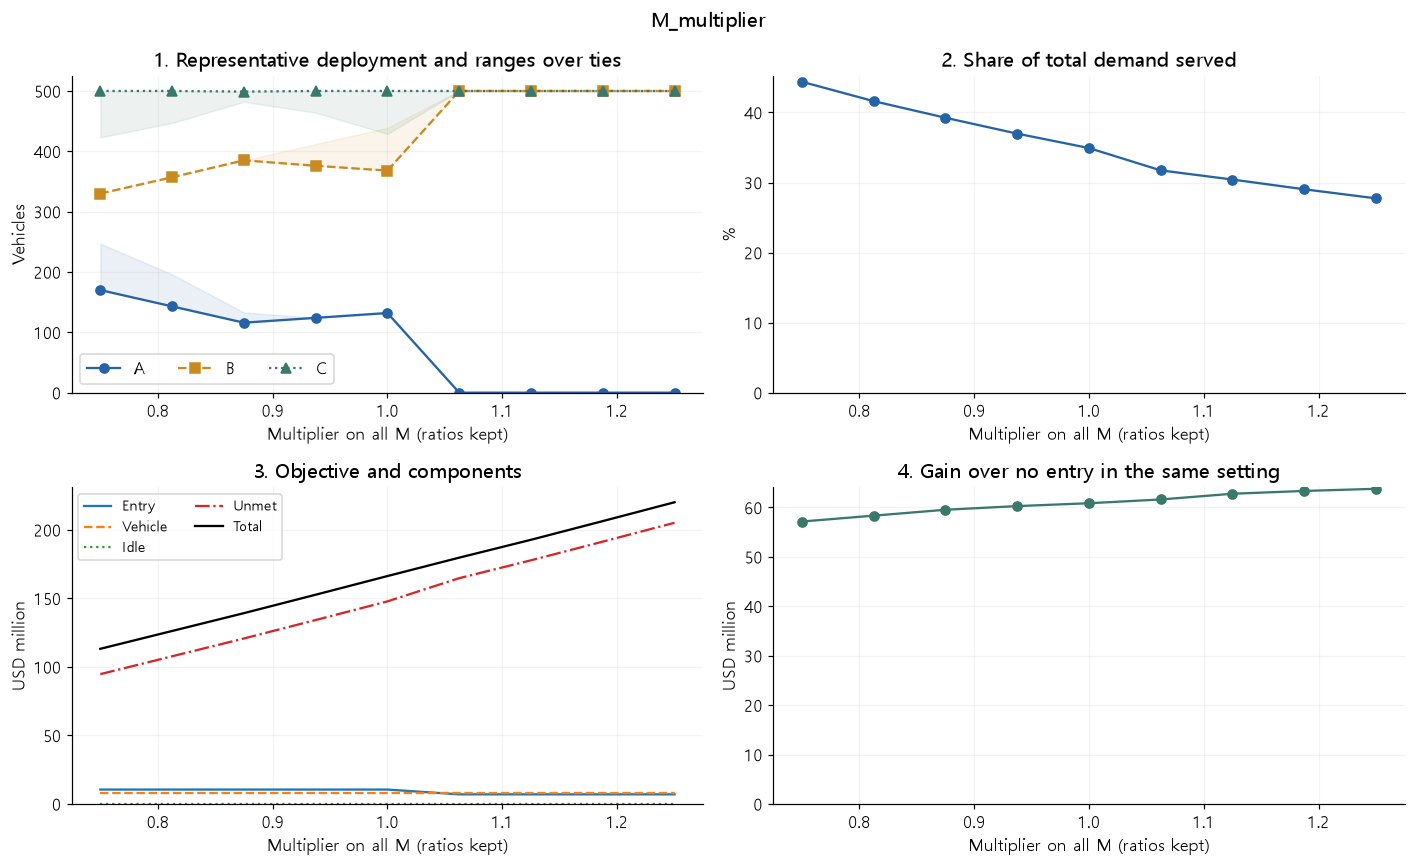

**M_multiplier: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,0.7500,"(170, 330, 500)",78,44.3944,1.197929e+06,1.131897e+08,5.714871e+07
1,0.8125,"(143, 357, 500)",54,41.6251,1.078785e+06,1.261931e+08,5.834015e+07
2,0.8750,"(116, 385, 499)",18,39.2517,9.595842e+05,1.391960e+08,5.953216e+07
3,0.9375,"(124, 376, 500)",37,36.9833,8.854041e+05,1.526491e+08,6.027396e+07
4,1.0000,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
5,1.0625,"(0, 500, 500)",1,31.7384,1.101112e+06,1.796959e+08,6.161688e+07
6,1.1250,"(0, 500, 500)",1,30.4275,9.855308e+05,1.927349e+08,6.277269e+07
7,1.1875,"(0, 500, 500)",1,29.0376,9.284810e+05,2.063593e+08,6.334319e+07
8,1.2500,"(0, 500, 500)",1,27.7384,8.851378e+05,2.201207e+08,6.377662e+07


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
0.7500,"(170, 330, 500)",78,"17,033,841.3949","7,562,070.6649","9,471,770.7300","1,197,929.3351",44.3944,86.3250,"10,500,000.0000","7,972,000.0000",0.0000,"94,717,707.3000","113,189,707.3000","170,338,413.9487","57,148,706.6487","(170, 330, 423)","(247, 330, 500)","-370,531.9241",9.4671,"-53,074,152.0750","-3,705,319.2412"
0.8125,"(143, 357, 500)",54,"18,453,328.1778","7,681,214.5497","10,772,113.6281","1,078,785.4503",41.6251,87.6851,"10,500,000.0000","7,972,000.0000",0.0000,"107,721,136.2812","126,193,136.2812","184,533,281.7778","58,340,145.4966","(143, 357, 447)","(196, 357, 500)","-251,388.0393",6.6978,"-40,070,723.0938","-2,513,880.3934"
0.8750,"(116, 385, 499)",18,"19,872,814.9607","7,800,415.7757","12,072,399.1850","959,584.2243",39.2517,89.0458,"10,500,000.0000","7,972,000.0000",0.0000,"120,723,991.8500","139,195,991.8500","198,728,149.6069","59,532,157.7569","(116, 385, 482)","(133, 385, 499)","-132,186.8133",4.3244,"-27,067,867.5250","-1,321,868.1331"
0.9375,"(124, 376, 500)",37,"21,292,301.7436","7,874,595.9272","13,417,705.8164","885,404.0728",36.9833,89.8926,"10,500,000.0000","7,972,000.0000",0.0000,"134,177,058.1641","152,649,058.1641","212,923,017.4359","60,273,959.2719","(124, 376, 464)","(124, 412, 500)","-58,006.6618",2.0561,"-13,614,801.2109","-580,066.6181"
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.0625,"(0, 500, 500)",1,"24,131,275.3094","7,658,887.5570","16,472,387.7524","1,101,112.4430",31.7384,87.4302,"7,000,000.0000","7,972,000.0000",0.0000,"164,723,877.5241","179,695,877.5241","241,312,753.0941","61,616,875.5700","(0, 500, 500)","(0, 500, 500)","-273,715.0320",-3.1888,"13,432,018.1491","762,849.6800"
1.1250,"(0, 500, 500)",1,"25,550,762.0923","7,774,469.1780","17,776,292.9143","985,530.8220",30.4275,88.7496,"7,000,000.0000","7,972,000.0000",0.0000,"177,762,929.1431","192,734,929.1431","255,507,620.9231","62,772,691.7800","(0, 500, 500)","(0, 500, 500)","-158,133.4110",-4.4997,"26,471,069.7681","1,918,665.8900"
1.1875,"(0, 500, 500)",1,"26,970,248.8752","7,831,519.0496","19,138,729.8256","928,480.9504",29.0376,89.4009,"7,000,000.0000","7,972,000.0000",0.0000,"191,387,298.2559","206,359,298.2559","269,702,488.7522","63,343,190.4963","(0, 500, 500)","(0, 500, 500)","-101,083.5394",-5.8896,"40,095,438.8809","2,489,164.6063"
1.2500,"(0, 500, 500)",1,"28,389,735.6581","7,874,862.1575","20,514,873.5006","885,137.8425",27.7384,89.8957,"7,000,000.0000","7,972,000.0000",0.0000,"205,148,735.0062","220,120,735.0062","283,897,356.5813","63,776,621.5750","(0, 500, 500)","(0, 500, 500)","-57,740.4315",-7.1888,"53,856,875.6312","2,922,595.6850"


**Sampled intervals with a change in the optimal allocation set:** 0.75 → 0.8125, 0.8125 → 0.875, 0.875 → 0.9375, 0.9375 → 1, 1 → 1.0625. These intervals do not identify exact switching thresholds without further evaluation.

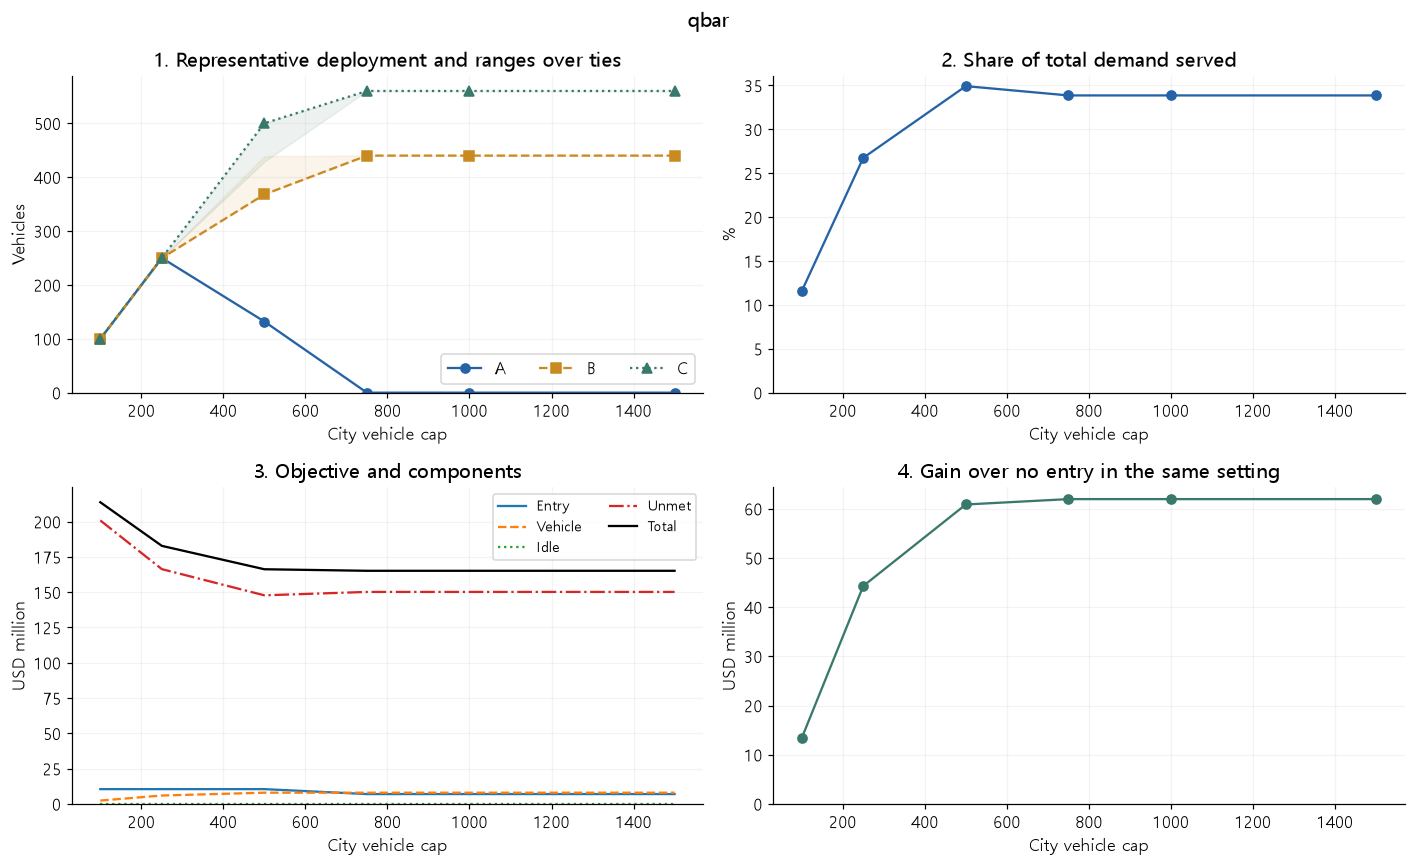

**qbar: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,100.0,"(100, 100, 100)",1,11.5711,0.000000e+00,2.137295e+08,1.338840e+07
1,250.0,"(250, 250, 250)",1,26.7581,4.927654e+05,1.828245e+08,4.429335e+07
2,500.0,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
3,750.0,"(0, 440, 560)",1,33.8679,1.067984e+06,1.651697e+08,6.194816e+07
4,1000.0,"(0, 440, 560)",1,33.8679,1.067984e+06,1.651697e+08,6.194816e+07
5,1500.0,"(0, 440, 560)",1,33.8679,1.067984e+06,1.651697e+08,6.194816e+07


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
100.0000,"(100, 100, 100)",1,"22,711,788.5265","2,628,000.0000","20,083,788.5265",0.0000,11.5711,100.0000,"10,500,000.0000","2,391,600.0000",0.0000,"200,837,885.2650","213,729,485.2650","227,117,885.2650","13,388,400.0000","(100, 100, 100)","(100, 100, 100)","-5,304,602.5890",-23.3562,"47,465,625.8900","-47,465,625.8900"
250.0000,"(250, 250, 250)",1,"22,711,788.5265","6,077,234.5890","16,634,553.9375","492,765.4110",26.7581,92.4998,"10,500,000.0000","5,979,000.0000",0.0000,"166,345,539.3750","182,824,539.3750","227,117,885.2650","44,293,345.8900","(250, 250, 250)","(250, 250, 250)","-1,855,368.0000",-8.1692,"16,560,680.0000","-16,560,680.0000"
500.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
750.0000,"(0, 440, 560)",1,"22,711,788.5265","7,692,016.0235","15,019,772.5030","1,067,983.9765",33.8679,87.8084,"7,000,000.0000","7,972,000.0000",0.0000,"150,197,725.0300","165,169,725.0300","227,117,885.2650","61,948,160.2350","(0, 440, 560)","(0, 440, 560)","-240,586.5655",-1.0593,"-1,094,134.3450","1,094,134.3450"
"1,000.0000","(0, 440, 560)",1,"22,711,788.5265","7,692,016.0235","15,019,772.5030","1,067,983.9765",33.8679,87.8084,"7,000,000.0000","7,972,000.0000",0.0000,"150,197,725.0300","165,169,725.0300","227,117,885.2650","61,948,160.2350","(0, 440, 560)","(0, 440, 560)","-240,586.5655",-1.0593,"-1,094,134.3450","1,094,134.3450"
"1,500.0000","(0, 440, 560)",1,"22,711,788.5265","7,692,016.0235","15,019,772.5030","1,067,983.9765",33.8679,87.8084,"7,000,000.0000","7,972,000.0000",0.0000,"150,197,725.0300","165,169,725.0300","227,117,885.2650","61,948,160.2350","(0, 440, 560)","(0, 440, 560)","-240,586.5655",-1.0593,"-1,094,134.3450","1,094,134.3450"


**Sampled intervals with a change in the optimal allocation set:** 100 → 250, 250 → 500, 500 → 750. These intervals do not identify exact switching thresholds without further evaluation.

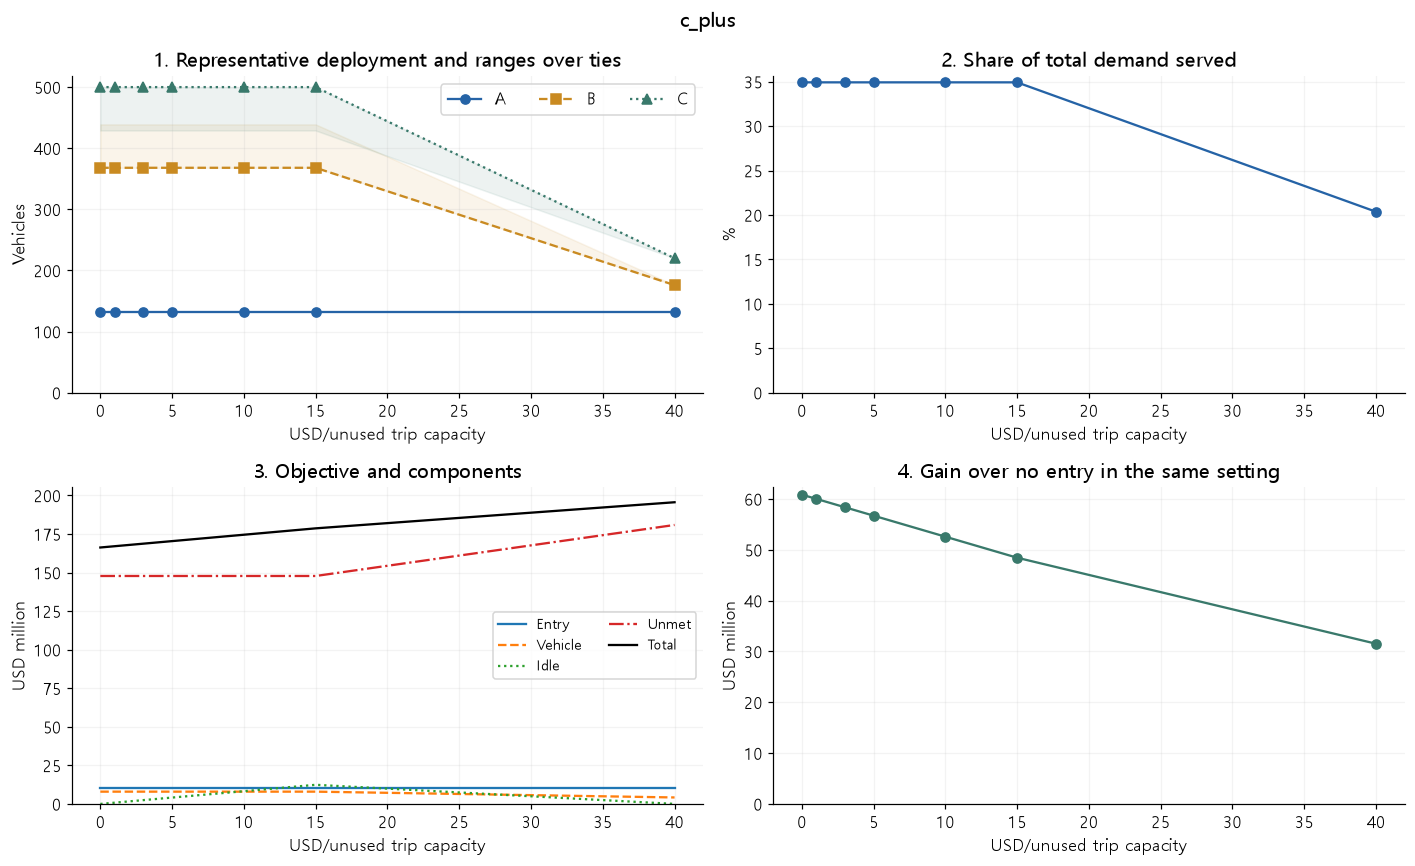

**c_plus: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,0.0,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,6.085403e+07
1,1.0,"(132, 368, 500)",72,34.9272,827397.411,1.670913e+08,6.002663e+07
2,3.0,"(132, 368, 500)",72,34.9272,827397.411,1.687461e+08,5.837183e+07
3,5.0,"(132, 368, 500)",72,34.9272,827397.411,1.704008e+08,5.671704e+07
4,10.0,"(132, 368, 500)",72,34.9272,827397.411,1.745378e+08,5.258005e+07
5,15.0,"(132, 368, 500)",72,34.9272,827397.411,1.786748e+08,4.844306e+07
6,40.0,"(132, 176, 220)",1,20.3631,453.411,1.955970e+08,3.152091e+07


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
0.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","827,397.4110","147,791,859.3750","167,091,256.7860","227,117,885.2650","60,026,628.4790","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"827,397.4110","-827,397.4110"
3.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","2,482,192.2330","147,791,859.3750","168,746,051.6080","227,117,885.2650","58,371,833.6570","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"2,482,192.2330","-2,482,192.2330"
5.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","4,136,987.0550","147,791,859.3750","170,400,846.4300","227,117,885.2650","56,717,038.8350","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"4,136,987.0550","-4,136,987.0550"
10.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","8,273,974.1100","147,791,859.3750","174,537,833.4850","227,117,885.2650","52,580,051.7800","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"8,273,974.1100","-8,273,974.1100"
15.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","12,410,961.1650","147,791,859.3750","178,674,820.5400","227,117,885.2650","48,443,064.7250","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"12,410,961.1650","-12,410,961.1650"
40.0000,"(132, 176, 220)",1,"22,711,788.5265","4,624,826.5890","18,086,961.9375",453.4110,20.3631,99.9902,"10,500,000.0000","4,209,216.0000","18,136.4400","180,869,619.3750","195,596,971.8150","227,117,885.2650","31,520,913.4500","(132, 176, 220)","(132, 176, 220)","-3,307,776.0000",-14.5641,"29,333,112.4400","-29,333,112.4400"


**Sampled intervals with a change in the optimal allocation set:** 15 → 40. These intervals do not identify exact switching thresholds without further evaluation.

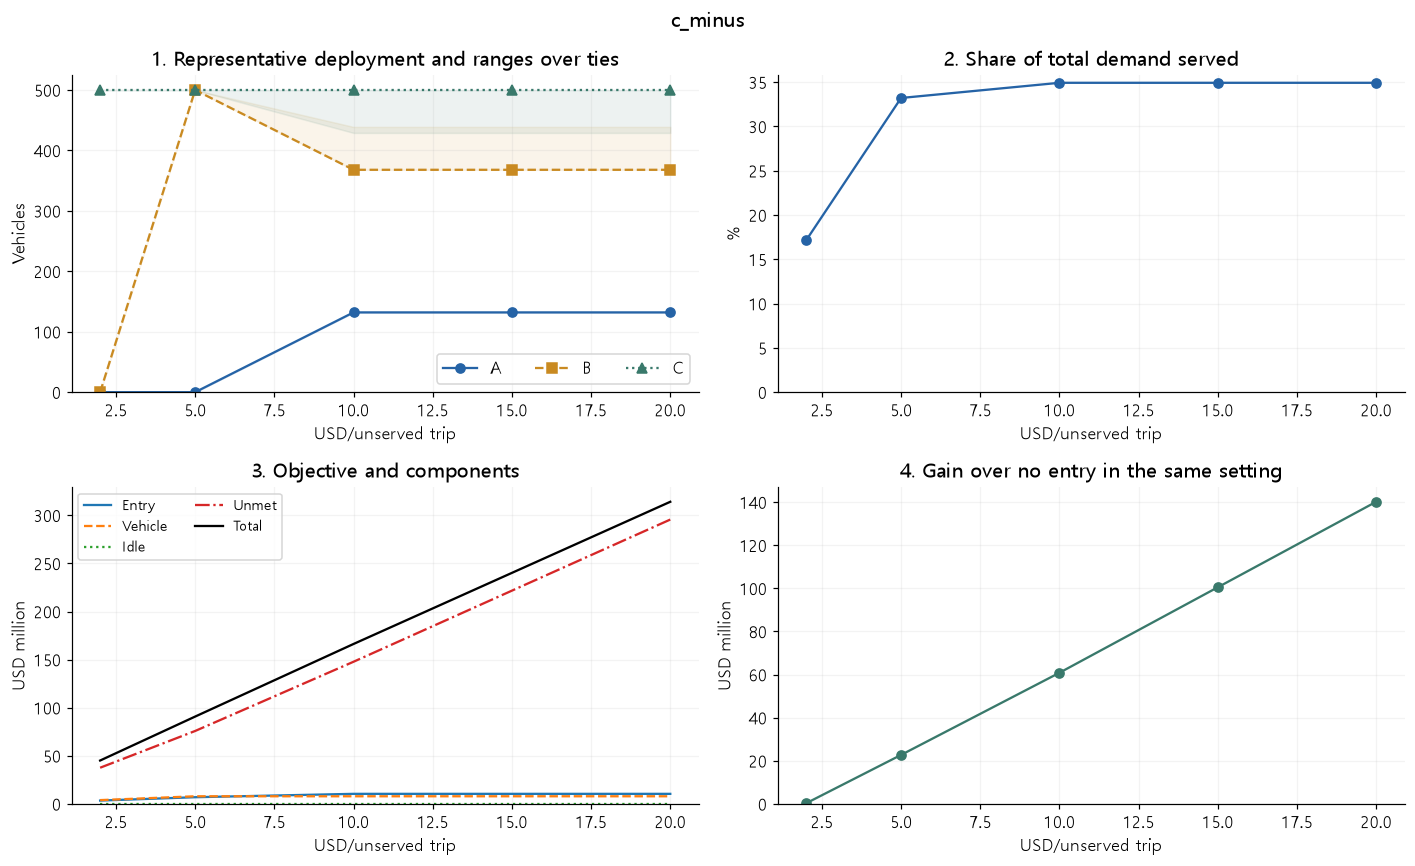

**c_minus: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,2.0,"(0, 0, 500)",1,17.1245,490727.930,4.513103e+07,2.925441e+05
1,5.0,"(0, 500, 500)",1,33.2132,1216694.064,9.081441e+07,2.274453e+07
2,10.0,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,6.085403e+07
3,15.0,"(132, 368, 500)",72,34.9272,827397.411,2.401598e+08,1.005170e+08
4,20.0,"(132, 368, 500)",72,34.9272,827397.411,3.140557e+08,1.401801e+08


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
2.0000,"(0, 0, 500)",1,"22,711,788.5265","3,889,272.0700","18,822,516.4565","490,727.9300",17.1245,88.7962,"3,500,000.0000","3,986,000.0000",0.0000,"37,645,032.9130","45,131,032.9130","45,423,577.0530","292,544.1400","(0, 0, 500)","(0, 0, 500)","-4,043,330.5190",-17.8028,"-121,132,826.4620","-60,561,481.7500"
5.0000,"(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"75,842,412.9525","90,814,412.9525","113,558,942.6325","22,744,529.6800","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"-75,449,446.4225","-38,109,496.2100"
10.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
15.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"221,687,789.0625","240,159,789.0625","340,676,827.8975","100,517,038.8350","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"73,895,929.6875","39,663,012.9450"
20.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"295,583,718.7500","314,055,718.7500","454,235,770.5300","140,180,051.7800","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"147,791,859.3750","79,326,025.8900"


**Sampled intervals with a change in the optimal allocation set:** 2 → 5, 5 → 10. These intervals do not identify exact switching thresholds without further evaluation.

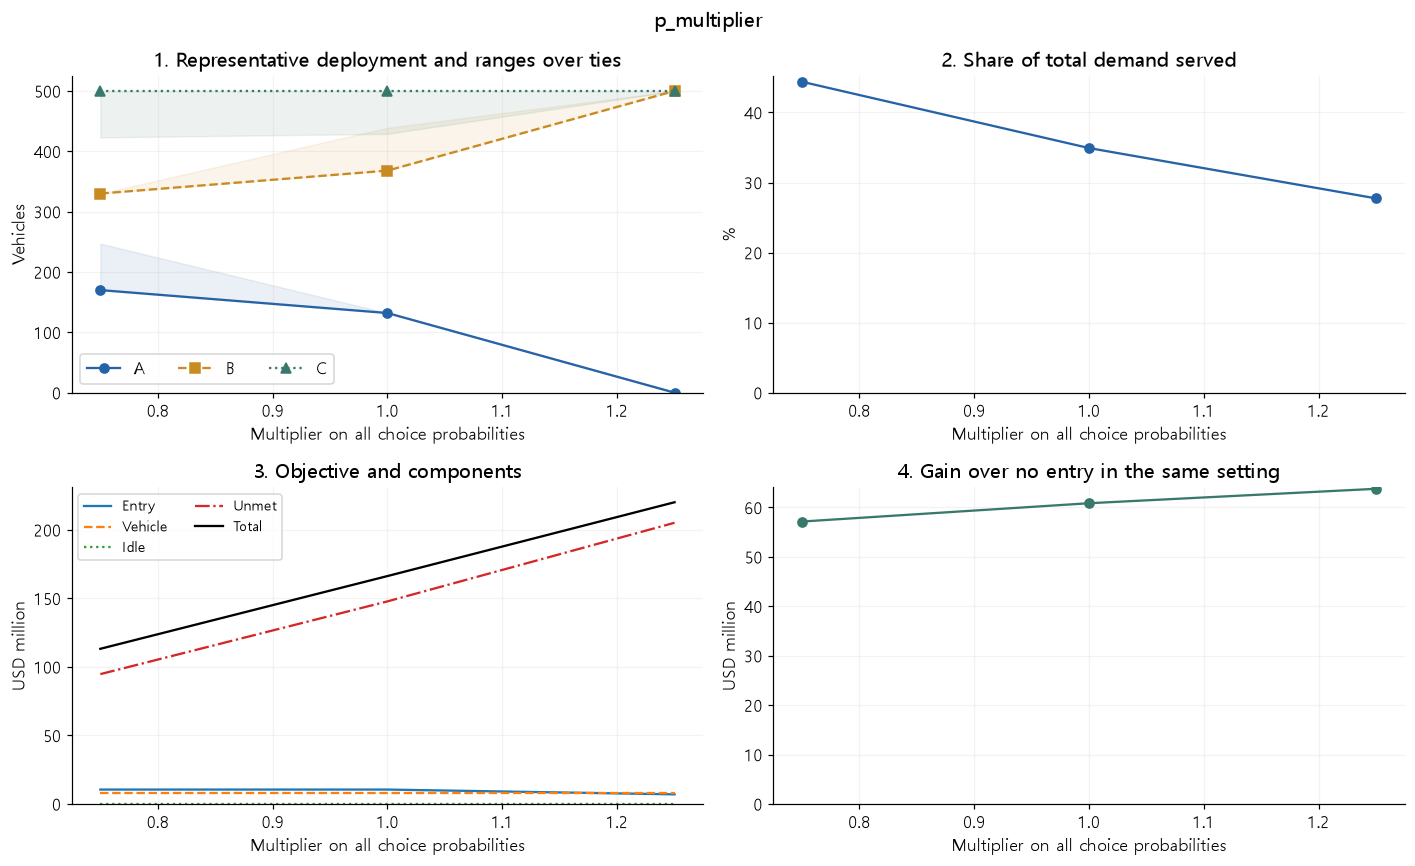

**p_multiplier: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,0.75,"(170, 330, 500)",78,44.3944,1.197929e+06,1.131897e+08,5.714871e+07
1,1.00,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
2,1.25,"(0, 500, 500)",1,27.7384,8.851378e+05,2.201207e+08,6.377662e+07


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
0.7500,"(170, 330, 500)",78,"17,033,841.3949","7,562,070.6649","9,471,770.7300","1,197,929.3351",44.3944,86.3250,"10,500,000.0000","7,972,000.0000",0.0000,"94,717,707.3000","113,189,707.3000","170,338,413.9487","57,148,706.6487","(170, 330, 423)","(247, 330, 500)","-370,531.9241",9.4671,"-53,074,152.0750","-3,705,319.2412"
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.2500,"(0, 500, 500)",1,"28,389,735.6581","7,874,862.1575","20,514,873.5006","885,137.8425",27.7384,89.8957,"7,000,000.0000","7,972,000.0000",0.0000,"205,148,735.0062","220,120,735.0062","283,897,356.5813","63,776,621.5750","(0, 500, 500)","(0, 500, 500)","-57,740.4315",-7.1888,"53,856,875.6312","2,922,595.6850"


**Sampled intervals with a change in the optimal allocation set:** 0.75 → 1, 1 → 1.25. These intervals do not identify exact switching thresholds without further evaluation.

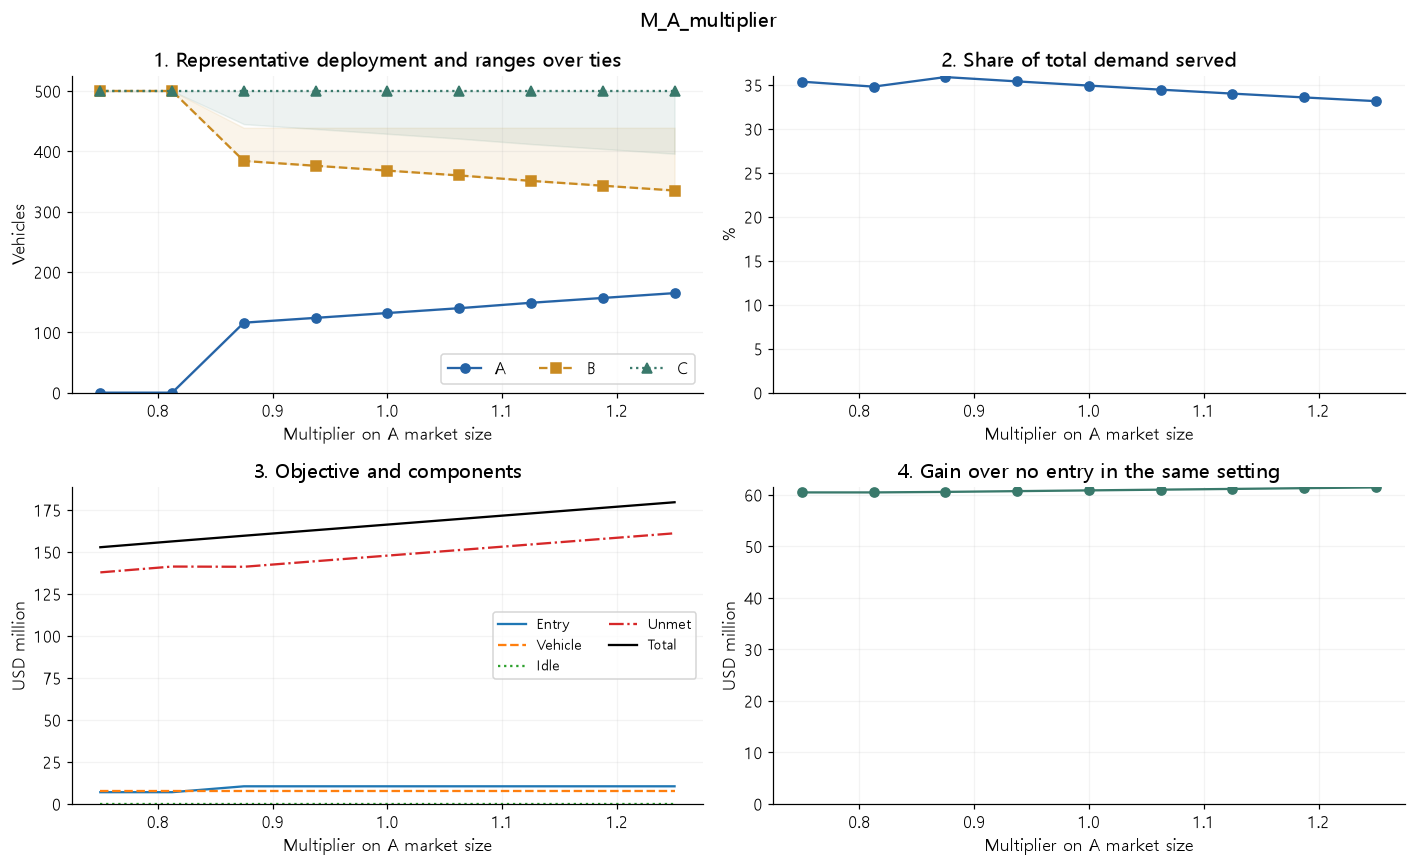

**M_A_multiplier: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,0.7500,"(0, 500, 500)",1,35.3734,1.216694e+06,1.527870e+08,6.046106e+07
1,0.8125,"(0, 500, 500)",1,34.8074,1.216694e+06,1.562545e+08,6.046106e+07
2,0.8750,"(116, 384, 500)",56,35.8941,8.567245e+05,1.596222e+08,6.056075e+07
3,0.9375,"(124, 376, 500)",64,35.4032,8.420610e+05,1.629430e+08,6.070739e+07
4,1.0000,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
5,1.0625,"(140, 360, 500)",80,34.4635,8.132303e+05,1.695896e+08,6.099570e+07
6,1.1250,"(149, 351, 500)",89,34.0139,7.989463e+05,1.729142e+08,6.113854e+07
7,1.1875,"(157, 343, 500)",97,33.5791,7.842827e+05,1.762351e+08,6.128517e+07
8,1.2500,"(165, 335, 500)",105,33.1568,7.696192e+05,1.795559e+08,6.143181e+07


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
0.7500,"(0, 500, 500)",1,"21,324,809.0745","7,543,305.9360","13,781,503.1385","1,216,694.0640",35.3734,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"137,815,031.3850","152,787,031.3850","213,248,090.7450","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",0.4461,"-13,476,827.9900","-392,966.5300"
0.8125,"(0, 500, 500)",1,"21,671,553.9375","7,543,305.9360","14,128,248.0015","1,216,694.0640",34.8074,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"141,282,480.0150","156,254,480.0150","216,715,539.3750","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-0.1198,"-10,009,379.3600","-392,966.5300"
0.8750,"(116, 384, 500)",56,"22,018,298.8005","7,903,275.4811","14,115,023.3194","856,724.5189",35.8941,90.2200,"10,500,000.0000","7,972,000.0000",0.0000,"141,150,233.1937","159,622,233.1937","220,182,988.0050","60,560,754.8113","(116, 384, 445)","(116, 439, 500)","-29,327.1079",0.9669,"-6,641,626.1813","-293,271.0787"
0.9375,"(124, 376, 500)",64,"22,365,043.6635","7,917,939.0351","14,447,104.6284","842,060.9649",35.4032,90.3874,"10,500,000.0000","7,972,000.0000",0.0000,"144,471,046.2844","162,943,046.2844","223,650,436.6350","60,707,390.3506","(124, 376, 437)","(124, 439, 500)","-14,663.5539",0.4759,"-3,320,813.0906","-146,635.5394"
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.0625,"(140, 360, 500)",80,"23,058,533.3895","7,946,769.7260","15,111,763.6635","813,230.2740",34.4635,90.7165,"10,500,000.0000","7,972,000.0000",0.0000,"151,117,636.6350","169,589,636.6350","230,585,333.8950","60,995,697.2600","(140, 360, 421)","(140, 439, 500)","14,167.1370",-0.4638,"3,325,777.2600","141,671.3700"
1.1250,"(149, 351, 500)",89,"23,405,278.2525","7,961,053.6969","15,444,224.5556","798,946.3031",34.0139,90.8796,"10,500,000.0000","7,972,000.0000",0.0000,"154,442,245.5563","172,914,245.5563","234,052,782.5250","61,138,536.9688","(149, 351, 412)","(149, 439, 500)","28,451.1079",-0.9133,"6,650,386.1813","284,511.0788"
1.1875,"(157, 343, 500)",97,"23,752,023.1155","7,975,717.2508","15,776,305.8647","784,282.7492",33.5791,91.0470,"10,500,000.0000","7,972,000.0000",0.0000,"157,763,058.6469","176,235,058.6469","237,520,231.1550","61,285,172.5081","(157, 343, 404)","(157, 439, 500)","43,114.6618",-1.3481,"9,971,199.2719","431,146.6181"
1.2500,"(165, 335, 500)",105,"24,098,767.9785","7,990,380.8048","16,108,387.1738","769,619.1952",33.1568,91.2144,"10,500,000.0000","7,972,000.0000",0.0000,"161,083,871.7375","179,555,871.7375","240,987,679.7850","61,431,808.0475","(165, 335, 396)","(165, 439, 500)","57,778.2157",-1.7704,"13,292,012.3625","577,782.1575"


**Sampled intervals with a change in the optimal allocation set:** 0.8125 → 0.875, 0.875 → 0.9375, 0.9375 → 1, 1 → 1.0625, 1.0625 → 1.125, 1.125 → 1.1875, 1.1875 → 1.25. These intervals do not identify exact switching thresholds without further evaluation.

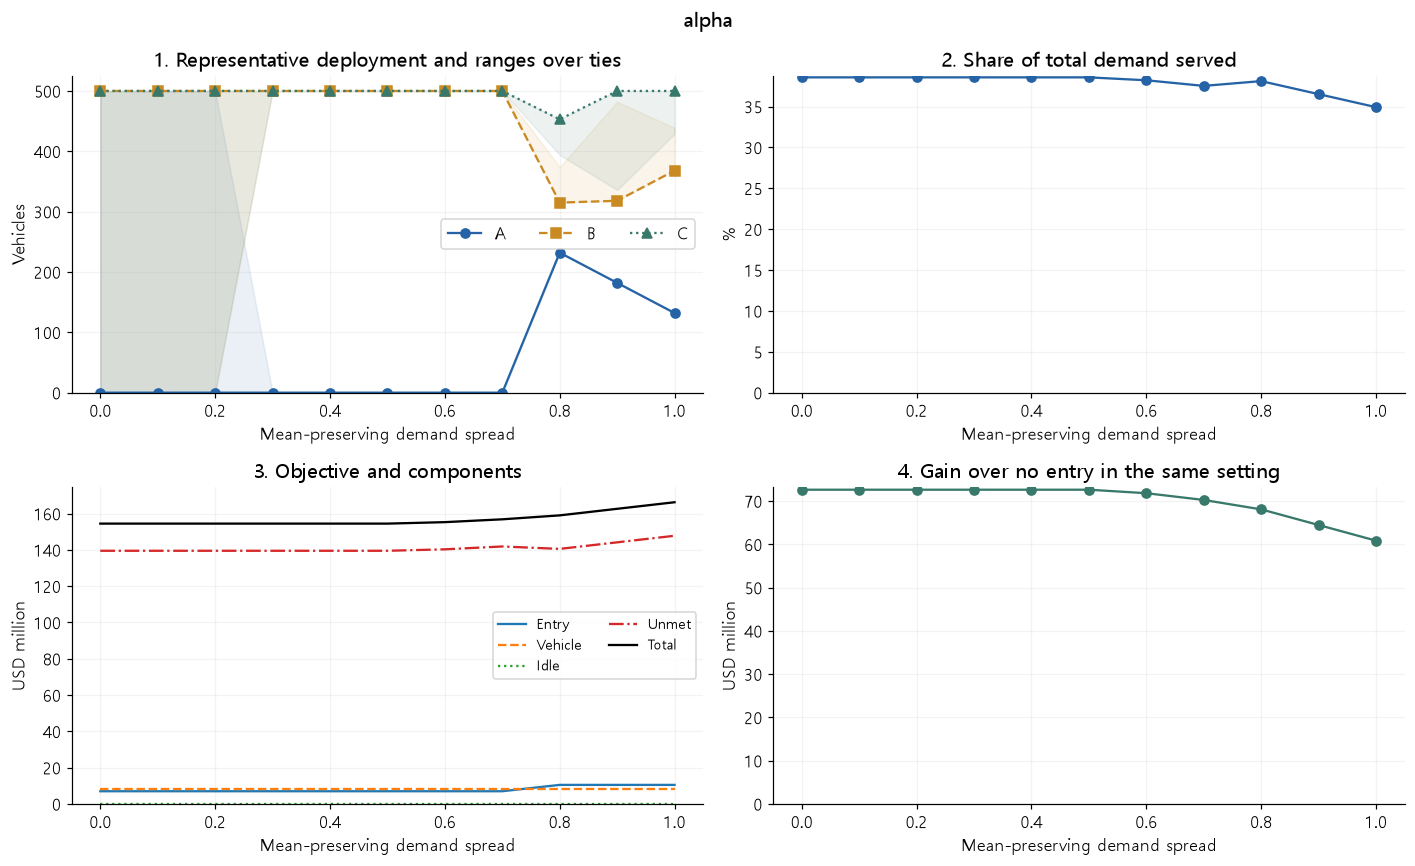

**alpha: selected comparisons**

,Input value,Representative allocation,Number of optimal q vectors,Service rate (%),Mean unused capacity,Objective,Improvement
0,0.0,"(0, 500, 500)",3,38.5703,0.0000,1.544899e+08,7.262800e+07
1,0.1,"(0, 500, 500)",3,38.5703,0.0000,1.544899e+08,7.262800e+07
2,0.2,"(0, 500, 500)",3,38.5703,0.0000,1.544899e+08,7.262800e+07
3,0.3,"(0, 500, 500)",1,38.5703,0.0000,1.544899e+08,7.262800e+07
4,0.4,"(0, 500, 500)",1,38.5703,0.0000,1.544899e+08,7.262800e+07
5,0.5,"(0, 500, 500)",1,38.5703,0.0000,1.544899e+08,7.262800e+07
6,0.6,"(0, 500, 500)",1,38.2145,80798.4475,1.552979e+08,7.182002e+07
7,0.7,"(0, 500, 500)",1,37.5280,236724.9487,1.568571e+08,7.026075e+07
8,0.8,"(232, 315, 453)",60,38.1115,104189.3905,1.590318e+08,6.808611e+07
9,0.9,"(182, 318, 500)",165,36.5197,465717.8322,1.626471e+08,6.447082e+07


Input value,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
0.0000,"(0, 500, 500)",3,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 0, 0)","(500, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.1000,"(0, 500, 500)",3,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 0, 0)","(500, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.2000,"(0, 500, 500)",3,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 0, 0)","(500, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.3000,"(0, 500, 500)",1,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 500, 500)","(0, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.4000,"(0, 500, 500)",1,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 500, 500)","(0, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.5000,"(0, 500, 500)",1,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 500, 500)","(0, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.6000,"(0, 500, 500)",1,"22,711,788.5265","8,679,201.5525","14,032,586.9740","80,798.4475",38.2145,99.0776,"7,000,000.0000","7,972,000.0000",0.0000,"140,325,869.7402","155,297,869.7402","227,117,885.2650","71,820,015.5248","(0, 500, 500)","(0, 500, 500)","746,598.9635",3.2873,"-10,965,989.6348","10,965,989.6348"
0.7000,"(0, 500, 500)",1,"22,711,788.5265","8,523,275.0513","14,188,513.4752","236,724.9487",37.5280,97.2977,"7,000,000.0000","7,972,000.0000",0.0000,"141,885,134.7519","156,857,134.7519","227,117,885.2650","70,260,750.5131","(0, 500, 500)","(0, 500, 500)","590,672.4623",2.6007,"-9,406,724.6231","9,406,724.6231"
0.8000,"(232, 315, 453)",60,"22,711,788.5265","8,655,810.6095","14,055,977.9170","104,189.3905",38.1115,98.8106,"10,500,000.0000","7,972,000.0000",0.0000,"140,559,779.1696","159,031,779.1696","227,117,885.2650","68,086,106.0954","(232, 315, 394)","(232, 374, 453)","723,208.0205",3.1843,"-7,232,080.2054","7,232,080.2054"
0.9000,"(182, 318, 500)",165,"22,711,788.5265","8,294,282.1678","14,417,506.3587","465,717.8322",36.5197,94.6836,"10,500,000.0000","7,972,000.0000",0.0000,"144,175,063.5873","162,647,063.5873","227,117,885.2650","64,470,821.6777","(182, 318, 336)","(182, 482, 500)","361,679.5788",1.5925,"-3,616,795.7877","3,616,795.7877"


**Sampled intervals with a change in the optimal allocation set:** 0.2 → 0.3, 0.7 → 0.8, 0.8 → 0.9, 0.9 → 1. These intervals do not identify exact switching thresholds without further evaluation.

**Interpretation:** Read served demand, service rate, and improvement together, and examine intervals where the optimal allocation set changes.

In [9]:
for name,values,change,xlabel,divisor in sweep_specs:
    results=run_sweep(name,values,change)
    plot_sweep(name,results,xlabel,divisor)
    if name=='Q':assert np.all(np.diff([a['rep']['cost'] for v,a in results])<=TOL_USD)
    if name=='c_plus' and SHORTAGE:
        assert all(a['rep']['unused']==0 for v,a in results)
        assert all(abs(a['rep']['gain']-b['gain'])<TOL_USD for v,a in results)
    if name in ['M_multiplier','M_A_multiplier','p_multiplier','alpha'] and SHORTAGE:
        assert all(abs(a['rep']['gain']-b['gain'])<TOL_USD for v,a in results)
if SHORTAGE:
    note('**Interpretation:** Increasing Q raises served demand up to 1,500 vehicles, after which city capacity limits bind. '
         'Changes in common F, K, or c- may affect improvement while leaving allocations unchanged within the sampled range. '
         'When all allocated capacity is used, changes in M, p, or variability leave service and improvement unchanged, while demand, service rate, and unmet demand loss change. '
         '**The idle penalty remains a relevant model parameter; it has no cost effect when O=0.**')
else:
    note('**Interpretation:** Read served demand, service rate, and improvement together, and examine intervals where the optimal allocation set changes.')


### 3-2. City-specific parameter changes
Change one city input while holding the corresponding inputs in other cities fixed. Distinguish resolution of tied allocations from large performance changes. For c+, whose baseline is zero, use absolute values 0, 1, 3, and 5; for qbar use 100, 500, and 1,000.


**M: one city at a time**

,Modified city,Setting,Setting definition,Representative allocation,Number of optimal q vectors,Service rate (%),Objective,Improvement
0,A,0.75,Baseline multiplier,"(0, 500, 500)",1,35.373,1.527870e+08,6.046106e+07
1,A,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
2,A,1.25,Baseline multiplier,"(165, 335, 500)",105,33.157,1.795559e+08,6.143181e+07
3,B,0.75,Baseline multiplier,"(170, 330, 500)",1,37.597,1.483001e+08,5.974682e+07
4,B,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
5,B,1.25,Baseline multiplier,"(0, 500, 500)",1,31.596,1.833754e+08,6.281344e+07
6,C,0.75,Baseline multiplier,"(132, 440, 428)",16,38.479,1.435307e+08,5.974845e+07
7,C,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
8,C,1.25,Baseline multiplier,"(132, 368, 500)",72,31.993,1.891394e+08,6.181721e+07


**kappa: one city at a time**

,Modified city,Setting,Setting definition,Representative allocation,Number of optimal q vectors,Service rate (%),Objective,Improvement
9,A,0.75,Baseline multiplier,"(0, 500, 500)",1,33.213,1.666568e+08,6.046106e+07
10,A,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
11,A,1.25,Baseline multiplier,"(264, 236, 500)",204,36.199,1.633756e+08,6.374231e+07
12,B,0.75,Baseline multiplier,"(266, 234, 500)",1,32.602,1.715448e+08,5.557309e+07
13,B,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
14,B,1.25,Baseline multiplier,"(148, 352, 500)",1,37.579,1.602420e+08,6.687587e+07
15,C,0.75,Baseline multiplier,"(267, 440, 293)",1,32.143,1.725876e+08,5.453033e+07
16,C,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
17,C,1.25,Baseline multiplier,"(132, 368, 500)",1,38.494,1.581630e+08,6.895493e+07


**F: one city at a time**

...

**qbar: one city at a time**

,Modified city,Setting,Setting definition,Representative allocation,Number of optimal q vectors,Service rate (%),Objective,Improvement
57,A,100.0,Absolute value,"(0, 500, 500)",1,33.213,1.666568e+08,6.046106e+07
58,A,500.0,Absolute value,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
59,A,1000.0,Absolute value,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
60,B,100.0,Absolute value,"(400, 100, 500)",1,32.767,1.711706e+08,5.594725e+07
61,B,500.0,Absolute value,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
62,B,1000.0,Absolute value,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
63,C,100.0,Absolute value,"(400, 500, 100)",61,31.731,1.735230e+08,5.359487e+07
64,C,500.0,Absolute value,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
65,C,1000.0,Absolute value,"(0, 440, 560)",1,33.868,1.651697e+08,6.194816e+07


**p: one city at a time**

,Modified city,Setting,Setting definition,Representative allocation,Number of optimal q vectors,Service rate (%),Objective,Improvement
66,A,0.75,Baseline multiplier,"(0, 500, 500)",1,35.373,1.527870e+08,6.046106e+07
67,A,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
68,A,1.25,Baseline multiplier,"(165, 335, 500)",105,33.157,1.795559e+08,6.143181e+07
69,B,0.75,Baseline multiplier,"(170, 330, 500)",1,37.597,1.483001e+08,5.974682e+07
70,B,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
71,B,1.25,Baseline multiplier,"(0, 500, 500)",1,31.596,1.833754e+08,6.281344e+07
72,C,0.75,Baseline multiplier,"(132, 440, 428)",16,38.479,1.435307e+08,5.974845e+07
73,C,1.00,Baseline multiplier,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
74,C,1.25,Baseline multiplier,"(132, 368, 500)",72,31.993,1.891394e+08,6.181721e+07


Parameter,Modified city,Setting,Setting definition,Representative allocation,Number of optimal q vectors,Mean demand,Mean served demand,Mean unmet demand,Mean unused capacity,Service rate (%),Utilization (%),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,No-entry baseline,Improvement,City minima across optimal q vectors,City maxima across optimal q vectors,Improvement reevaluated at baseline inputs,Feasible at baseline inputs
M,A,0.7500,Baseline multiplier,"(0, 500, 500)",1,"21,324,809.0745","7,543,305.9360","13,781,503.1385","1,216,694.0640",35.3734,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"137,815,031.3850","152,787,031.3850","213,248,090.7450","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","60,461,059.3600",True
M,A,1.0000,Baseline multiplier,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
M,A,1.2500,Baseline multiplier,"(165, 335, 500)",105,"24,098,767.9785","7,990,380.8048","16,108,387.1738","769,619.1952",33.1568,91.2144,"10,500,000.0000","7,972,000.0000",0.0000,"161,083,871.7375","179,555,871.7375","240,987,679.7850","61,431,808.0475","(165, 335, 396)","(165, 439, 500)","60,564,945.8900",True
M,B,0.7500,Baseline multiplier,"(170, 330, 500)",1,"20,804,691.7800","7,821,882.3325","12,982,809.4475","938,117.6675",37.5967,89.2909,"10,500,000.0000","7,972,000.0000",0.0000,"129,828,094.4750","148,300,094.4750","208,046,917.8000","59,746,823.3250","(170, 330, 500)","(170, 330, 500)","60,521,145.8900",True
M,B,1.0000,Baseline multiplier,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
M,B,1.2500,Baseline multiplier,"(0, 500, 500)",1,"24,618,885.2730","7,778,544.1400","16,840,341.1330","981,455.8600",31.5958,88.7962,"7,000,000.0000","7,972,000.0000",0.0000,"168,403,411.3300","183,375,411.3300","246,188,852.7300","62,813,441.4000","(0, 500, 500)","(0, 500, 500)","60,461,059.3600",True
M,C,0.7500,Baseline multiplier,"(132, 440, 428)",16,"20,327,917.5934","7,822,045.3471","12,505,872.2462","937,954.6529",38.4793,89.2928,"10,500,000.0000","7,972,000.0000",0.0000,"125,058,722.4625","143,530,722.4625","203,279,175.9337","59,748,453.4712","(132, 440, 413)","(147, 440, 428)","60,848,987.9900",True
M,C,1.0000,Baseline multiplier,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
M,C,1.2500,Baseline multiplier,"(132, 368, 500)",72,"25,095,659.4596","8,028,920.6065","17,066,738.8531","731,079.3935",31.9933,91.6543,"10,500,000.0000","7,972,000.0000",0.0000,"170,667,388.5312","189,139,388.5312","250,956,594.5963","61,817,206.0650","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
kappa,A,0.7500,Baseline multiplier,"(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"151,684,825.9050","166,656,825.9050","227,117,885.2650","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","60,461,059.3600",True


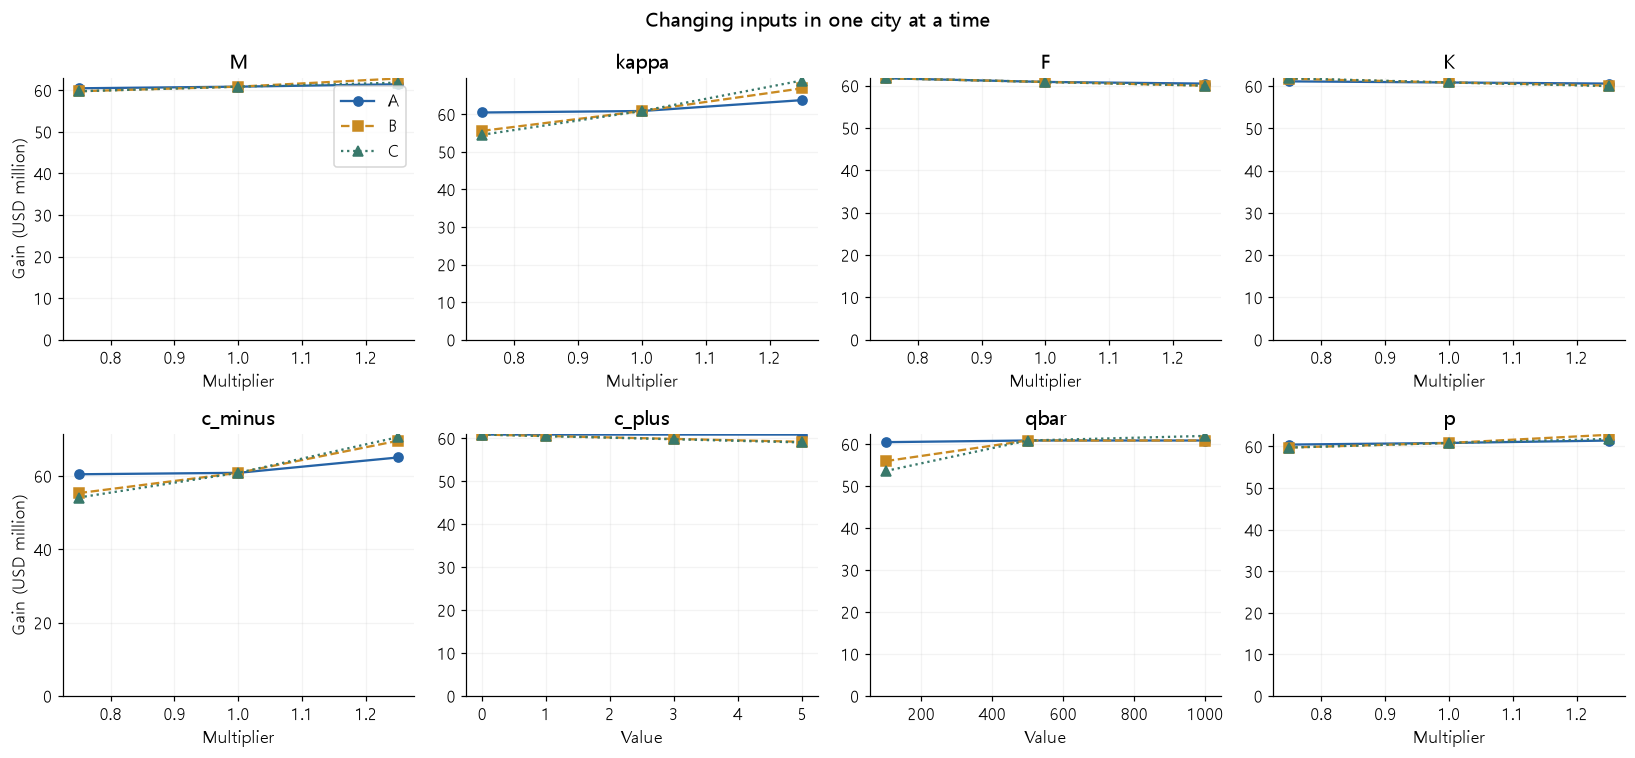

Lower F or K, or higher kappa or c-, can shift vehicles toward the affected city. Changes in one city M or p can also alter allocations when demand is close to capacity. Applying c+ >= 1 to one city often resolves the B-C tie and yields a unique optimum. Stability under a common parameter change does not imply insensitivity to differences across cities.

In [10]:
city_rows=[]
for key in ['M','kappa','F','K','c_minus','c_plus','qbar','p']:
    for c,city in enumerate(cities):
        levels=[0,1,3,5] if key=='c_plus' else ([100,500,1000] if key=='qbar' else [.75,1.,1.25])
        for level in levels:
            d=deepcopy(BASE)
            if key=='p':d['p'][:,c]=BASE['p'][:,c]*level
            else:d[key][c]=level if key in ['qbar','c_plus'] else BASE[key][c]*level
            a=solve(d,f'{city}:{key}={level}')
            row={'Parameter':key,'Modified city':city,'Setting':level,'Setting definition':'Absolute value' if key in ['qbar','c_plus'] else 'Baseline multiplier',**report_row(a)}
                                                    
                                                           
            feasible=np.all(np.array(a['rep']['q'])<=BASE['qbar']) and sum(a['rep']['q'])<=BASE['Q']
            row['Improvement reevaluated at baseline inputs']=evaluate(BASE,a['rep']['q'])['gain'] if feasible else np.nan
            row['Feasible at baseline inputs']=feasible
            city_rows.append(row)
city_sensitivity=pd.DataFrame(city_rows)
for key,group in city_sensitivity.groupby('Parameter',sort=False):
    show(key+': one city at a time',group[['Modified city','Setting','Setting definition','Representative allocation','Number of optimal q vectors','Service rate (%)','Objective','Improvement']].round(3))
detail('City-specific sensitivity: costs, service, and optimal allocation ranges',city_sensitivity)
fig,axes=plt.subplots(2,4,figsize=(15,7))
for ax,(key,group) in zip(axes.flat,city_sensitivity.groupby('Parameter',sort=False)):
    for c,city in enumerate(cities):
        g=group[group['Modified city']==city]
        ax.plot(g['Setting'],g['Improvement']/1e6,marker=['o','s','^'][c],linestyle=['-','--',':'][c],color=COLORS[c],label=city)
    ax.set_title(key);ax.set_xlabel(L('Absolute value' if key in ['qbar','c_plus'] else 'Baseline multiplier','Value' if key in ['qbar','c_plus'] else 'Multiplier'))
    ax.grid(alpha=.15);ax.set_ylim(bottom=0)
for ax in axes[:,0]:ax.set_ylabel(L('Improvement (million USD)','Gain (USD million)'))
axes[0,0].legend();fig.suptitle(L('Improvement when changing one city input','Changing inputs in one city at a time'))
showfig(fig,'15_city_sensitivity')
note('Lower F or K, or higher kappa or c-, can shift vehicles toward the affected city. '
     'Changes in one city M or p can also alter allocations when demand is close to capacity. '
     'Applying c+ >= 1 to one city often resolves the B-C tie and yields a unique optimum. '
     'Stability under a common parameter change does not imply insensitivity to differences across cities.')

## 4. Mean-demand decisions and scenario sampling
### 4-1. Common evaluation scenarios
Solve a single-scenario problem using each city's mean p, then evaluate its optimal allocations under the original ten demand scenarios.


In [11]:
mean_data=deepcopy(BASE);mean_data['p']=BASE['p'].mean(axis=0,keepdims=True)
mean_answer=solve(mean_data,'annual mean demand')
mean_evaluations=[evaluate(BASE,qq) for qq in mean_answer['oracle']['samples']]
if SHORTAGE:
    assert mean_answer['oracle']['count']==3
    assert all(abs(r['cost']-b['cost'])<TOL_USD for r in mean_evaluations)
show(f'All mean-demand optima evaluated under the original {S} scenarios',pd.DataFrame([
 {'q':r['q'],'Evaluation cost under common scenarios':r['cost'],'Extra cost relative to scenario optimum':r['cost']-b['cost'],'Service rate (%)':100*r['service_rate']} for r in mean_evaluations]))
extra=max(r['cost']-b['cost'] for r in mean_evaluations)
note(f'Maximum extra cost of mean-demand allocations relative to the scenario optimum: {extra:,.2f} USD. '
     +('Zero extra cost here reflects linear losses under persistent unmet demand; it does not imply that uncertainty is generally irrelevant.' if SHORTAGE else 'When demand is close to capacity, a mean-demand allocation can incur additional losses.'))

**All mean-demand optima evaluated under the original 10 scenarios**

,q,Evaluation cost under common scenarios,Extra cost relative to scenario optimum,Service rate (%)
0,"(0, 500, 500)",1.666568e+08,392966.53,33.213174
1,"(500, 0, 500)",1.720506e+08,5786775.51,30.838280
2,"(500, 500, 0)",1.744030e+08,8139157.55,29.802527


Maximum extra cost of mean-demand allocations relative to the scenario optimum: 8,139,157.55 USD. When demand is close to capacity, a mean-demand allocation can incur additional losses.

### 4-2. Scenario counts of 50, 100, and 500, with five seeds each
Sample with replacement from the ten specified scenarios at equal probability. Repeated scenarios are allowed; each sampled row has weight $1/|S|$.

This tests sampling stability under the assumed discrete distribution. It does not estimate or validate an actual demand distribution. Reevaluate every sampled allocation under the original ten-scenario distribution to separate changes in sample means from changes in allocation quality.


**Scenario count by seed**

,S,seed,Distinct scenario count,"Sample mean p (A,B,C)",Representative allocation,Number of optimal q vectors,Sample mean demand,Sample objective,Sample service rate (%),Objective under common distribution,Improvement under common distribution,Extra cost under common distribution
0,50,590,10,"(0.009, 0.009, 0.011)","(132, 440, 428)",1,2.285819e+07,1.650570e+08,35.871998,1.662689e+08,60848987.99,5037.90
1,50,591,10,"(0.011, 0.009, 0.009)","(329, 176, 495)",1,2.212617e+07,1.633715e+08,34.512179,1.679896e+08,59128305.89,1725720.00
2,50,592,10,"(0.01, 0.011, 0.012)","(0, 500, 500)",1,2.576314e+07,1.947086e+08,30.234994,1.666568e+08,60461059.36,392966.53
3,50,593,10,"(0.011, 0.009, 0.009)","(324, 176, 500)",1,2.189501e+07,1.600872e+08,35.320807,1.679458e+08,59172105.89,1681920.00
4,50,594,10,"(0.011, 0.009, 0.01)","(132, 368, 500)",1,2.244595e+07,1.647692e+08,34.822433,1.662639e+08,60854025.89,0.00
5,100,590,10,"(0.009, 0.009, 0.01)","(132, 439, 429)",1,2.249026e+07,1.618388e+08,36.253833,1.662639e+08,60854025.89,0.00
6,100,591,10,"(0.01, 0.009, 0.009)","(324, 176, 500)",1,2.184493e+07,1.593408e+08,35.514171,1.679458e+08,59172105.89,1681920.00
7,100,592,10,"(0.01, 0.011, 0.011)","(0, 500, 500)",1,2.414693e+07,1.786986e+08,32.195698,1.666568e+08,60461059.36,392966.53
8,100,593,10,"(0.01, 0.009, 0.009)","(132, 368, 500)",1,2.198555e+07,1.599969e+08,35.628205,1.662639e+08,60854025.89,0.00
9,100,594,10,"(0.01, 0.01, 0.01)","(132, 368, 500)",1,2.226102e+07,1.618476e+08,35.593436,1.662639e+08,60854025.89,0.00


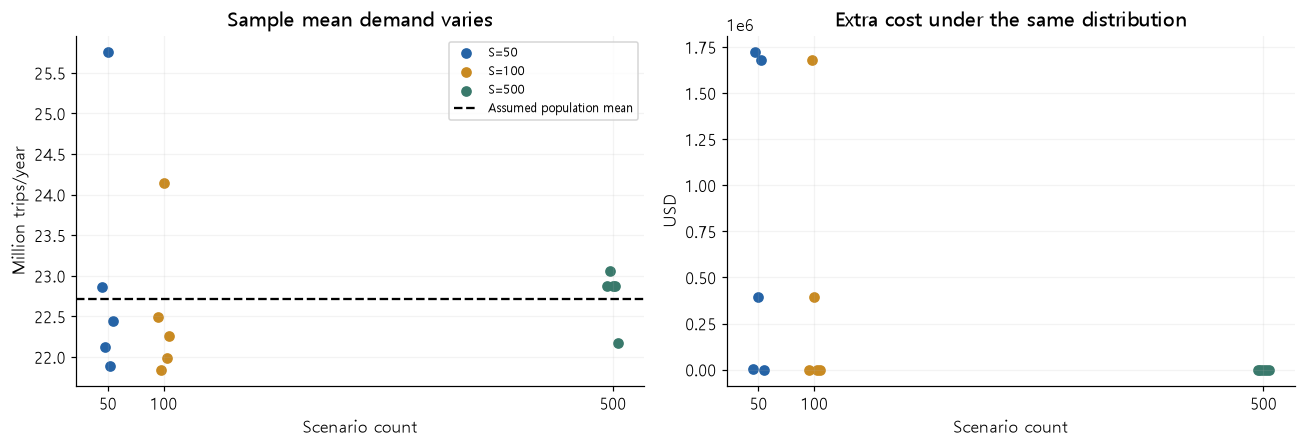

A change in the sample objective alone does not imply a worse allocation: sample demand and the no-entry baseline also change. Five seeds do not establish a general convergence rate.

In [12]:
sample_rows=[];SEEDS=[590,591,592,593,594]
for ns in [50,100,500]:
    for seed in SEEDS:
        rng=np.random.default_rng(seed);indices=rng.integers(0,len(BASE['p']),size=ns)
        d=deepcopy(BASE);d['p']=BASE['p'][indices].copy()
        a=solve(d,f'sample S={ns} seed={seed}');pop=evaluate(BASE,a['rep']['q'])
        sample_rows.append({'S':ns,'seed':seed,'Distinct scenario count':int(len(np.unique(indices))),
            'Sample mean p (A,B,C)':tuple(np.round(d['p'].mean(axis=0),3)),'Representative allocation':a['rep']['q'],'Number of optimal q vectors':a['oracle']['count'],
            'Sample mean demand':a['rep']['demand'],'Sample objective':a['rep']['cost'],'Sample service rate (%)':100*a['rep']['service_rate'],
            'Objective under common distribution':pop['cost'],'Improvement under common distribution':pop['gain'],
            'Extra cost under common distribution':pop['cost']-b['cost']})
sample_results=pd.DataFrame(sample_rows)
show('Scenario count by seed',sample_results)
if SHORTAGE:assert np.allclose(sample_results['Extra cost under common distribution'],0,atol=TOL_USD,rtol=0)
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for c,ns in enumerate([50,100,500]):
    g=sample_results[sample_results['S']==ns]
    axes[0].scatter(np.full(len(g),ns)+np.linspace(-5,5,len(g)),g['Sample mean demand']/1e6,label=f'S={ns}',color=COLORS[c])
    axes[1].scatter(np.full(len(g),ns)+np.linspace(-5,5,len(g)),g['Extra cost under common distribution'],color=COLORS[c])
axes[0].axhline(b['demand']/1e6,color='black',linestyle='--',label=L('Assumed distribution mean','Assumed population mean'))
axes[0].set_ylabel(L('Million trips/year','Million trips/year'));axes[0].legend(fontsize=8)
axes[0].set_title(L('Sample mean demand varies','Sample mean demand varies'))
axes[1].set_ylabel('USD');axes[1].set_title(L('Extra cost under the same distribution','Extra cost under the same distribution'))
for ax in axes:ax.set_xticks([50,100,500]);ax.set_xlabel(L('Scenario count','Scenario count'));ax.grid(alpha=.15)
showfig(fig,'17_sampling')
note('A change in the sample objective alone does not imply a worse allocation: sample demand and the no-entry baseline also change. '
     +('In this experiment, sample demand exceeds capacity throughout, preserving the optimal allocation set and performance under the common distribution. ' if SHORTAGE else '')
     +'Five seeds do not establish a general convergence rate.')

## 5. Interpretation and export
- **Demand-capacity balance:** City demand differences affect allocation when demand is close to capacity. The baseline allocates 132 vehicles to A and 868 to B and C.
- **M and p scales:** Demand enters through D=Mp, so equal proportional changes in M and p have the same model effect.
- **Capacity constraints:** qbar, Q, and M are sensitivity parameters; their effects depend on whether the instance remains supply-constrained.
- **Ties:** Ten equiprobable scenarios and c+=0 create marginal-value steps. B and C share a broad 8/10 step, producing 72 tied allocations. City-specific idle penalties can resolve these ties.
- **Decisions and performance:** Common changes in F and K can change improvement without changing allocation. Entry into A becomes unattractive near F=USD 3.9 million. The unmet demand coefficient also affects entry decisions.
- **Idle penalties:** A common c+ can lower improvement while preserving allocation; a city-specific c+ can resolve B-C ties.
- **Sampling:** At 50 scenarios, allocations vary across seeds. The scenario count affects allocation quality in this instance.
- **Scope:** The low p candidate values are experimental assumptions chosen to examine behavior near capacity. The results assess a literature-informed synthetic instance rather than recommend actual city fleets.


In [13]:
assert all(all(r['checks'].values()) for r in SOLVE_LOG)
assert all(r['gap']<=1e-8 for r in SOLVE_LOG)
all_sensitivity=pd.concat([table.assign(experiment=name) for name,table in sensitivity_tables.items()],ignore_index=True)
note(f'**Validation:** MILP-DP comparisons, excluding cached inputs: **{len(SOLVE_LOG)} passed**, '
     f'edge cases **{len(edge_answers)} passed**, common/additional sensitivity **{len(all_sensitivity)} rows**, '
     f'city-specific sensitivity **{len(city_sensitivity)} rows**, sampling **{len(sample_results)} rows**. '
     f'Python {sys.version.split()[0]}, SciPy {scipy.__version__}.')
                                         
EXPORT_CSV=False
if EXPORT_CSV:
    edge_table.to_csv('annual_v3_edges.csv',index=False,encoding='utf-8-sig')
    all_sensitivity.to_csv('annual_v3_sensitivity.csv',index=False,encoding='utf-8-sig')
    city_sensitivity.to_csv('annual_v3_city_sensitivity.csv',index=False,encoding='utf-8-sig')
    sample_results.to_csv('annual_v3_sampling.csv',index=False,encoding='utf-8-sig')

**Validation:** MILP-DP comparisons, excluding cached inputs: **160 passed**, edge cases **8 passed**, common/additional sensitivity **98 rows**, city-specific sensitivity **75 rows**, sampling **15 rows**. Python 3.12.14, SciPy 1.18.1.